# **PDG  - TIME UP AND GO**
### Predecesores.
*   **Juan David Patiño**
*   **Daniel Montezuma**
*  **Diego Mueses**

### Actuales.
* **Esteban Guarin Valencia**
* **Santiago Gomez Robledo**
* **Heiner Danit Rincon**
* **Juan Jose Arias Gallego**

# Codigo PDG Predecesor

## **Código**

In [ ]:
def cargar_datos_json(ruta_archivo):
    """Carga datos desde un archivo JSON."""
    try:
        with open(ruta_archivo, 'r') as file:
            return json.load(file)
    except FileNotFoundError:
        print(f"Error: No se encontró el archivo '{ruta_archivo}'")
        return None
    except json.JSONDecodeError:
        print(f"Error: El archivo '{ruta_archivo}' no contiene un JSON válido")
        return None

## **Graficar Señales Base**

In [ ]:

import json
import matplotlib.pyplot as plt
import numpy as np

def plot_json_data_with_phases(json_data, timestamp_index=None, timestamp_value=None,
                               phases=None, colors=None, alpha=0.2):
    """
    Grafica los datos de un JSON, permitiendo filtrar por índice o valor específico de timestamp.
    Resalta fases del movimiento con colores de fondo diferentes.

    Parámetros:
    - json_data: Datos JSON a procesar
    - timestamp_index: Índice (posición) del timestamp a procesar (opcional)
    - timestamp_value: Valor específico del timestamp a procesar (opcional)
    - phases: Lista de diccionarios con las fases a resaltar. Cada fase debe tener:
        - 'name': Nombre de la fase
        - 'start': Tiempo de inicio de la fase
        - 'end': Tiempo de fin de la fase
        - 'color': (opcional) Color específico para esta fase
    - colors: Lista de colores para las fases (si no se especifica un color por fase)
    - alpha: Transparencia para las áreas coloreadas
    """
    # Valores por defecto
    if phases is None:
        phases = []

    if colors is None:
        colors = ['lightpink', 'lightgreen', 'lightblue', 'lightyellow', 'lightcyan']

    # Seleccionar timestamps a procesar
    timestamps = list(json_data.keys())
    timestamps_to_process = []

    if timestamp_index is not None:
        if 0 <= timestamp_index < len(timestamps):
            timestamps_to_process = [timestamps[timestamp_index]]
        else:
            print(f"Error: Índice {timestamp_index} fuera de rango. Rango válido: 0-{len(timestamps)-1}")
            return
    elif timestamp_value is not None:
        if timestamp_value in json_data:
            timestamps_to_process = [timestamp_value]
        else:
            print(f"Error: Timestamp '{timestamp_value}' no encontrado en los datos")
            return
    else:
        timestamps_to_process = timestamps

    for timestamp in timestamps_to_process:
        print(f"Procesando timestamp: {timestamp}")
        prueba = json_data[timestamp]

        for lado, datos in prueba.items():
            tiempos = [d["t"] for d in datos]
            valores = {key: [d[key] for d in datos] for key in ["a", "b", "g", "x", "y", "z"]}

            plt.figure(figsize=(15, 6))

            # Resaltar las fases del movimiento
            for i, phase in enumerate(phases):
                color = phase.get('color', colors[i % len(colors)])
                plt.axvspan(phase['start'], phase['end'], alpha=alpha, color=color, label=phase['name'])

                # Líneas verticales al inicio y fin de cada fase
                plt.axvline(x=phase['start'], color='gray', linestyle='--', alpha=0.7)
                plt.axvline(x=phase['end'], color='gray', linestyle='--', alpha=0.7)

                # Añadir etiquetas
                y_min, y_max = plt.ylim()
                plt.text(phase['start'] + (phase['end'] - phase['start'])/2, y_max * 0.95,
                         phase['name'], horizontalalignment='center', verticalalignment='top',
                         fontsize=9, bbox=dict(facecolor='white', alpha=0.6))

            # Graficar todos los valores
            for key, vals in valores.items():
                plt.plot(tiempos, vals, label=key, linewidth=1)

            plt.xlabel("Tiempo (ms)")
            plt.ylabel("Valores")
            plt.title(f"Datos de '{lado}' en {timestamp} - Fases de Movimiento")
            plt.legend(loc='upper right')
            plt.grid(True)
            plt.tight_layout()
            plt.show()


## **Transformada de Fourier (FFT)**

In [ ]:
# TRANSFORMADA DE FOURIER (FFT)
import json
import numpy as np
import matplotlib.pyplot as plt

def fft_json_data(json_data, timestamp_index=None, fs=50):  # fs: frecuencia de muestreo en Hz
    # Convertir las claves de timestamp a una lista ordenada
    timestamps = sorted(json_data.keys())

    # Si se especifica un índice de timestamp, usar solo ese
    if timestamp_index is not None:
        if 0 <= timestamp_index < len(timestamps):
            selected_timestamp = timestamps[timestamp_index]
            timestamps = [selected_timestamp]
            print(f"Analizando el timestamp {selected_timestamp} (índice {timestamp_index})")
        else:
            print(f"Índice de timestamp no válido. Debe estar entre 0 y {len(timestamps)-1}")
            return

    # Proceder con el análisis de los timestamps seleccionados
    for timestamp in timestamps:
        prueba = json_data[timestamp]
        for lado, datos in prueba.items():
            valores = {key: [d[key] for d in datos] for key in ["a", "b", "g", "x", "y", "z"]}

            plt.figure(figsize=(12, 6))
            for key, señal in valores.items():
                señal_np = np.array(señal)
                N = len(señal_np)

                # Aplicar FFT
                fft_result = np.fft.fft(señal_np)
                fft_freqs = np.fft.fftfreq(N, d=1/fs)

                # Tomar solo frecuencias positivas
                idx = np.where(fft_freqs >= 0)
                fft_magnitude = np.abs(fft_result[idx])
                fft_freqs = fft_freqs[idx]

                plt.plot(fft_freqs, fft_magnitude, label=key)

            plt.title(f"FFT - '{lado}' en {timestamp}")
            plt.xlabel("Frecuencia (Hz)")
            plt.ylabel("Magnitud")
            plt.legend()
            plt.grid()
            plt.tight_layout()
            plt.show()


In [ ]:
def graficar_energia_y_derivada_con_fases(
        json_data, señal_key="a", sensor="derecha",
        tamaño_ventana=1.0, paso=0.1, fs=25,
        timestamp_index=None, aplicar_window=True,
        phases=None, alpha=0.2):

    # Obtener datos originales
    pruebas_data = json_data["pruebas"]
    timestamps = sorted(pruebas_data.keys())

    if timestamp_index is not None:
        timestamps = [timestamps[timestamp_index]]

    timestamp = timestamps[0]
    datos_sensor = pruebas_data[timestamp][sensor]

    señal_original = [d[señal_key] for d in datos_sensor if señal_key in d]
    tiempos_original = [d["t"]/1000.0 for d in datos_sensor]

    # FFT deslizante
    tiempos_fft, energia_fft = analisis_fourier_ventana_deslizante(
        json_data, señal_key, sensor, tamaño_ventana,
        paso, fs, timestamp_index, aplicar_window
    )

    # --- SOLO 2 SUBPLOTS ---
    fig, axs = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

    # --- Señal original ---
    axs[0].plot(tiempos_original, señal_original, 'b-', linewidth=1)
    axs[0].set_ylabel("Amplitud")
    axs[0].set_title(f"Señal Original - {sensor}/{señal_key}")
    axs[0].grid(True, linestyle='--', alpha=0.4)

    if phases:
        agregar_fases_al_grafico(axs[0], phases, alpha)

    # --- Energía FFT ---
    axs[1].plot(tiempos_fft, energia_fft, 'r-', linewidth=2, label="Energía espectral (FFT)")
    axs[1].set_ylabel("Energía")
    axs[1].set_xlabel("Tiempo (s)")
    axs[1].set_title(f"Energía Espectral (FFT) - Ventana: {tamaño_ventana}s, Paso: {paso}s")
    axs[1].grid(True, linestyle='--', alpha=0.4)
    axs[1].legend()

    if phases:
        agregar_fases_al_grafico(axs[1], phases, alpha)

    plt.tight_layout()
    plt.show()


## **Muestra**

In [ ]:
# señales disponibles ['a', 'b', 'g', 'x','y','z']
# sensores disponibles ['derecha', 'izquierda', 'espina_base']

ruta_archivo_TUG = "/20250709003.json"
datos_TUG = cargar_datos_json(ruta_archivo_TUG)

print("DATOS DE LA PRUEBA TUG")
print(datos_TUG)

ruta_archivo_FASES = "/20250709003.2.json"
datos_FASES = cargar_datos_json(ruta_archivo_FASES)

print("DATOS DE LAS FASES")
print(datos_FASES)

graficar_energia_y_derivada_con_fases(
                  datos_TUG,
                  señal_key='g',
                  sensor='espina_base',
                  tamaño_ventana=1.0,
                  paso=0.5,
                  fs=25,
                  timestamp_index=1,
                  aplicar_window=True,
                  phases=datos_FASES,  # Pasar las fases aquí
                  alpha=0.2
              )

Error: No se encontró el archivo '/20250709003.json'
DATOS DE LA PRUEBA TUG
None
Error: No se encontró el archivo '/20250709003.2.json'
DATOS DE LAS FASES
None


TypeError: 'NoneType' object is not subscriptable

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## **Domiciano**

In [ ]:
from scipy.signal import butter, filtfilt
import numpy as np
from scipy.signal import windows
from scipy.fft import fft
import json
import matplotlib.pyplot as plt

path = "20250709001.json"
lateral = "espina_base"
signal = "b"
comparingsignalA = "x"
comparingsignalB = "a"
indice_muestra = 1

patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())  # Obtener las claves en orden

def filter_signal(signal, cutoff_hz=3, fs=50.0, order=20):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff_hz / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    filtered = filtfilt(b, a, signal)
    return filtered

def cargar_datos_json(ruta_archivo):
    """Carga datos desde un archivo JSON."""
    try:
        with open(ruta_archivo, 'r') as file:
            return json.load(file)
    except FileNotFoundError:
        print(f"Error: No se encontró el archivo '{ruta_archivo}'")
        return None
    except json.JSONDecodeError:
        print(f"Error: El archivo '{ruta_archivo}' no contiene un JSON válido")
        return None


def energy_spectrum(signal, fs, window_size_samples, step_size_samples, apply_window=True):

    energies = []
    times = []

    num_samples = len(signal)

    for start in range(0, num_samples - window_size_samples + 1, step_size_samples):
        end = start + window_size_samples
        window = signal[start:end]

        if apply_window:
            window = window * np.hanning(window_size_samples)

        energy = np.sum(window ** 2)
        energies.append(energy)

        t_center = (start + end) / 2 / fs  # tiempo en segundos
        times.append(t_center)

    energies = np.array(energies)
    times = np.array(times)

    # Normalizar la energía
    if np.max(np.abs(energies)) > 0:
        energies = energies / np.max(np.abs(energies))

    return times, energies

def binary_threshold(signal: np.ndarray, threshold: float = 0.2) -> np.ndarray:
    return (signal >= threshold).astype(int)

def promediomovil(senal, ventana=50, fs=50):
    senal = np.array(senal, dtype=float)
    kernel = np.ones(ventana) / ventana
    prom = np.convolve(senal, kernel, mode='valid')

    # Normalizar entre 0 y 1
    if np.max(prom) != 0:
        prom = prom / np.max(prom)

    # Tiempo alineado al final de cada ventana
    t = (np.arange(len(prom)) + ventana - 1) / fs
    return t, prom




def derivar_senal(senal, fs=50):
    senal = np.array(senal, dtype=float)
    derivada = np.diff(senal) * fs
    # Eje de tiempo centrado entre las muestras
    t_deriv = np.arange(len(derivada)) / fs + (0.5 / fs)
    return t_deriv, derivada




if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]
    sample = patientdata[clave_muestra][lateral]
    asignal = np.array([d[signal] for d in sample])
    acomparingsignalA = np.array([d[comparingsignalA] for d in sample])
    acomparingsignalB = np.array([d[comparingsignalB] for d in sample])

    # senal va a estar entre 0 y 1.
    asignal = asignal/max(abs(asignal))
    acomparingsignalA = acomparingsignalA/max(abs(acomparingsignalA))
    acomparingsignalB = acomparingsignalB/max(abs(acomparingsignalB))

    asignalfiltered = filter_signal(asignal)
    time = [d["t"] / 1000.0 for d in sample]

    plt.plot(time, asignal)
    plt.plot(time, acomparingsignalA)
    plt.plot(time, acomparingsignalB)

    plt.xlabel("Tiempo (s)")
    plt.ylabel(f"Señal {signal}")
    plt.title(f"Muestra #{indice_muestra}: {clave_muestra}")
    plt.grid(True)

    times, energies = energy_spectrum(
      signal=asignalfiltered,
      fs=50,
      window_size_samples=50,
      step_size_samples=1,
      apply_window=True
    )
    #plt.plot(times, energies)

    t_movil, pmovil = promediomovil(energies, ventana=50)

    t_derivada, derivada = derivar_senal(energies);
    binary = binary_threshold(pmovil, threshold=0.2)

    plt.plot(t_movil, binary)
    #plt.plot(t_movil, pmovil)


    plt.show()


Error: No se encontró el archivo '20250709001.json'


TypeError: 'NoneType' object is not subscriptable

## **Fases**

## **Levantamiento y sentado  - OK ✅**




In [ ]:
# Variables de control
path = "20250709004.json"
lateral = "espina_base"
signal = "b"
indice_muestra = 2  # Cambia este valor para seleccionar la muestra deseada

patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())  # Obtener las claves en orden

if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]
    sample = patientdata[clave_muestra][lateral]
    asignal = np.array([d[signal] for d in sample])

    # senal va a estar entre 0 y 1.
    asignal = asignal/max(abs(asignal))
    asignalfiltered = filter_signal(asignal)
    time = [d["t"] / 1000.0 for d in sample]

    plt.plot(time, asignalfiltered)
    plt.xlabel("Tiempo (s)")
    plt.ylabel(f"Señal {signal}")
    plt.title(f"Muestra #{indice_muestra}: {clave_muestra}")
    plt.grid(True)

    times, energies = energy_spectrum(
      signal=asignalfiltered,
      fs=50,
      window_size_samples=50,
      step_size_samples=1,
      apply_window=True
    )
    plt.plot(times, energies)

    t_movil, pmovil = promediomovil(energies, ventana=50)

    #t_derivada, derivada = derivar_senal(energies);
    binary = binary_threshold(pmovil, threshold=0.2)

    plt.plot(t_movil, binary)
    plt.plot(t_movil, pmovil)


    plt.show()

else:
    print("Índice fuera de rango.")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def detectar_fases_tug(tiempo, senal_binaria, duracion_minima=0.5):
    """
    Detecta las fases de levantamiento y sentado en la prueba TUG

    Args:
        tiempo: array con los tiempos
        senal_binaria: señal binaria (0 o 1)
        duracion_minima: duración mínima en segundos para considerar una fase válida

    Returns:
        dict con información de las fases detectadas
    """

    # Encontrar transiciones
    transiciones = np.diff(senal_binaria.astype(int))
    indices_subida = np.where(transiciones == 1)[0] + 1  # De 0 a 1
    indices_bajada = np.where(transiciones == -1)[0] + 1  # De 1 a 0

    # Si la señal empieza en 1, agregar el índice 0 como subida
    if senal_binaria[0] == 1:
        indices_subida = np.concatenate([[0], indices_subida])

    # Si la señal termina en 1, agregar el último índice como bajada
    if senal_binaria[-1] == 1:
        indices_bajada = np.concatenate([indices_bajada, [len(senal_binaria)-1]])

    # Emparejar subidas con bajadas
    fases_movimiento = []
    min_indices = min(len(indices_subida), len(indices_bajada))

    for i in range(min_indices):
        inicio_mov = indices_subida[i]
        fin_mov = indices_bajada[i]

        if inicio_mov < fin_mov:  # Verificar que la secuencia sea correcta
            t_inicio = tiempo[inicio_mov]
            t_fin = tiempo[fin_mov]
            duracion = t_fin - t_inicio

            # Solo considerar movimientos que superen la duración mínima
            if duracion >= duracion_minima:
                fases_movimiento.append({
                    'inicio_tiempo': t_inicio,
                    'fin_tiempo': t_fin,
                    'duracion': duracion,
                    'inicio_indice': inicio_mov,
                    'fin_indice': fin_mov
                })

    # Clasificar las fases
    fases_clasificadas = {
        'levantamiento': None,
        'sentado': None,
        'todas_las_fases': fases_movimiento
    }

    if len(fases_movimiento) >= 1:
        fases_clasificadas['levantamiento'] = fases_movimiento[0]

    if len(fases_movimiento) >= 2:
        fases_clasificadas['sentado'] = fases_movimiento[-1]  # La última fase

    return fases_clasificadas

def graficar_fases_tug(tiempo, senal_original, senal_binaria, t_movil, pmovil, fases):
    """
    Grafica las señales y marca las fases detectadas
    """
    plt.figure(figsize=(12, 8))

    # Gráfico principal
    plt.plot(tiempo, senal_original, label='Señal Original', alpha=0.7)
    plt.plot(t_movil, pmovil, label='Promedio Móvil', linewidth=2)
    plt.plot(t_movil, senal_binaria, label='Señal Binaria', linewidth=2)

    # Marcar las fases
    colores = ['red', 'orange', 'purple', 'brown']

    for i, fase in enumerate(fases['todas_las_fases']):
        color = colores[i % len(colores)]
        plt.axvspan(fase['inicio_tiempo'], fase['fin_tiempo'],
                   alpha=0.3, color=color,
                   label=f'Fase {i+1}: {fase["duracion"]:.2f}s')

    # Destacar levantamiento y sentado si están identificados
    if fases['levantamiento']:
        plt.axvspan(fases['levantamiento']['inicio_tiempo'],
                   fases['levantamiento']['fin_tiempo'],
                   alpha=0.5, color='green',
                   label=f'LEVANTAMIENTO: {fases["levantamiento"]["duracion"]:.2f}s')

    if fases['sentado']:
        plt.axvspan(fases['sentado']['inicio_tiempo'],
                   fases['sentado']['fin_tiempo'],
                   alpha=0.5, color='blue',
                   label=f'SENTADO: {fases["sentado"]["duracion"]:.2f}s')

    plt.xlabel("Tiempo (s)")
    plt.ylabel("Señal")
    plt.title(f"Detección de Fases TUG")
    plt.grid(True)
    plt.legend()
    plt.show()

def imprimir_resumen_fases(fases):
    """
    Imprime un resumen de las fases detectadas
    """
    print("\n" + "="*50)
    print("RESUMEN DE FASES DETECTADAS")
    print("="*50)

    print(f"Total de fases de movimiento detectadas: {len(fases['todas_las_fases'])}")

    if fases['levantamiento']:
        lev = fases['levantamiento']
        print(f"\n🚶 FASE DE LEVANTAMIENTO:")
        print(f"   Tiempo inicio: {lev['inicio_tiempo']:.2f} s")
        print(f"   Tiempo fin: {lev['fin_tiempo']:.2f} s")
        print(f"   Duración: {lev['duracion']:.2f} s")
    else:
        print("\n❌ No se detectó fase de levantamiento")

    if fases['sentado']:
        sent = fases['sentado']
        print(f"\n🪑 FASE DE SENTADO:")
        print(f"   Tiempo inicio: {sent['inicio_tiempo']:.2f} s")
        print(f"   Tiempo fin: {sent['fin_tiempo']:.2f} s")
        print(f"   Duración: {sent['duracion']:.2f} s")
    else:
        print("\n❌ No se detectó fase de sentado")

    print(f"\n📊 TODAS LAS FASES:")
    for i, fase in enumerate(fases['todas_las_fases']):
        print(f"   Fase {i+1}: {fase['inicio_tiempo']:.2f}s - {fase['fin_tiempo']:.2f}s (Duración: {fase['duracion']:.2f}s)")

# Tu código principal modificado
path = "20250709001.json"
lateral = "espina_base"
signal = "b"
indice_muestra = 3

patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())

if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]
    sample = patientdata[clave_muestra][lateral]
    asignal = np.array([d[signal] for d in sample])

    # Senal va a estar entre 0 y 1.
    asignal = asignal/max(abs(asignal))
    asignalfiltered = filter_signal(asignal)
    time = [d["t"] / 1000.0 for d in sample]

    times, energies = energy_spectrum(
        signal=asignalfiltered,
        fs=50,
        window_size_samples=50,
        step_size_samples=1,
        apply_window=True
    )

    t_movil, pmovil = promediomovil(energies, ventana=50)
    binary = binary_threshold(pmovil, threshold=0.2)

    # NUEVA FUNCIONALIDAD: Detectar fases
    fases_detectadas = detectar_fases_tug(t_movil, binary, duracion_minima=0.5)

    # Mostrar resultados
    imprimir_resumen_fases(fases_detectadas)

    # Graficar con las fases marcadas
    graficar_fases_tug(time, asignalfiltered, binary, t_movil, pmovil, fases_detectadas)

else:
    print("Índice fuera de rango.")

## **Caminata - Ida / Vuelta**


In [ ]:
# Variables de control
path = "20250709008.json"
lateral = "izquierda"
signal = "g"
indice_muestra = 3  # Cambia este valor para seleccionar la muestra deseada

patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())  # Obtener las claves en orden

if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]
    sample = patientdata[clave_muestra][lateral]
    asignal = np.array([d[signal] for d in sample])

    # senal va a estar entre 0 y 1.
    asignal = asignal/max(abs(asignal))
    asignalfiltered = filter_signal(asignal)
    time = [d["t"] / 1000.0 for d in sample]

    plt.plot(time, asignalfiltered)
    plt.xlabel("Tiempo (s)")
    plt.ylabel(f"Señal {signal}")
    plt.title(f"Muestra #{indice_muestra}: {clave_muestra}")
    plt.grid(True)

    times, energies = energy_spectrum(
      signal=asignalfiltered,
      fs=50,
      window_size_samples=50,
      step_size_samples=1,
      apply_window=True
    )
    plt.plot(times, energies)

    t_movil, pmovil = promediomovil(energies, ventana=50)

    #t_derivada, derivada = derivar_senal(energies);
    binary = binary_threshold(pmovil, threshold=0.2)

    plt.plot(t_movil, binary)
    plt.plot(t_movil, pmovil)


    plt.show()

else:
    print("Índice fuera de rango.")

## Señales cortadas para caminatas ida y vuelta

In [ ]:
def extraer_fase(time, signal, inicio_ms, fin_ms):
    """
    Filtra la señal y el tiempo para quedarse solo con el segmento
    comprendido entre inicio_ms y fin_ms (en milisegundos).
    """
    inicio_s = inicio_ms / 1000.0
    fin_s = fin_ms / 1000.0

    mask = (np.array(time) >= inicio_s) & (np.array(time) <= fin_s)

    return np.array(time)[mask], np.array(signal)[mask]


##Caminata E Ida

###Izquierda

In [ ]:
path = "20250709003.json"
path_fases = "20250709003.2.json"
lateral = "izquierda"
signal = "g"
indice_muestra = 1
fase_a_analizar = "caminataIda"         # Nombre de la fase

patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())

with open(path_fases, "r") as f:
    fases_json = json.load(f)

if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]
    sample = patientdata[clave_muestra][lateral]

    # senal va a estar entre 0 y 1.
    asignal = np.array([d[signal] for d in sample])
    asignal = asignal / max(abs(asignal))
    asignalfiltered = filter_signal(asignal)
    time = np.array([d["t"] / 1000.0 for d in sample])

    # === Recortar la señal a la fase elegida ===
    inicio_ms = fases_json[fase_a_analizar]["inicio"]
    fin_ms = fases_json[fase_a_analizar]["fin"]

    time_fase, signal_fase = extraer_fase(time, asignalfiltered, inicio_ms, fin_ms)

    time_fase = time_fase - time_fase[0]

    # === Procesar solo la fase ===
    plt.plot(time_fase, signal_fase, label="Señal filtrada fase")

    times, energies = energy_spectrum(
        signal=signal_fase,
        fs=50,
        window_size_samples=50,
        step_size_samples=1,
        apply_window=True
    )
    plt.plot(times, energies, label="Energía")

    t_movil, pmovil = promediomovil(energies, ventana=50)

    #t_derivada, derivada = derivar_senal(energies);
    binary = binary_threshold(pmovil, threshold=0.2)

    plt.plot(t_movil, binary, label="Umbral binario")
    plt.plot(t_movil, pmovil, label="Promedio móvil")

    plt.xlabel("Tiempo (s)")
    plt.ylabel(f"Señal {signal}")
    plt.title(f"Muestra #{indice_muestra} - Fase: {fase_a_analizar}")
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("Índice fuera de rango.")


###Derecha

In [ ]:
path = "20250709003.json"
path_fases = "20250709003.2.json"
lateral = "derecha"
signal = "g"
indice_muestra = 1
fase_a_analizar = "caminataIda"         # Nombre de la fase

patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())

with open(path_fases, "r") as f:
    fases_json = json.load(f)

if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]
    sample = patientdata[clave_muestra][lateral]

    # senal va a estar entre 0 y 1.
    asignal = np.array([d[signal] for d in sample])
    asignal = asignal / max(abs(asignal))
    asignalfiltered = filter_signal(asignal)
    time = np.array([d["t"] / 1000.0 for d in sample])

    # === Recortar la señal a la fase elegida ===
    inicio_ms = fases_json[fase_a_analizar]["inicio"]
    fin_ms = fases_json[fase_a_analizar]["fin"]

    time_fase, signal_fase = extraer_fase(time, asignalfiltered, inicio_ms, fin_ms)

    time_fase = time_fase - time_fase[0]

    # === Procesar solo la fase ===
    plt.plot(time_fase, signal_fase, label="Señal filtrada fase")

    times, energies = energy_spectrum(
        signal=signal_fase,
        fs=50,
        window_size_samples=50,
        step_size_samples=1,
        apply_window=True
    )
    plt.plot(times, energies, label="Energía")

    t_movil, pmovil = promediomovil(energies, ventana=50)

    #t_derivada, derivada = derivar_senal(energies);
    binary = binary_threshold(pmovil, threshold=0.2)

    plt.plot(t_movil, binary, label="Umbral binario")
    plt.plot(t_movil, pmovil, label="Promedio móvil")

    plt.xlabel("Tiempo (s)")
    plt.ylabel(f"Señal {signal}")
    plt.title(f"Muestra #{indice_muestra} - Fase: {fase_a_analizar}")
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("Índice fuera de rango.")


##CaminataVuelta

###Izquierda

In [ ]:
path = "20250709003.json"
path_fases = "20250709003.2.json"
lateral = "izquierda"
signal = "g"
indice_muestra = 1
fase_a_analizar = "caminataVuelta"         # Nombre de la fase

patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())

with open(path_fases, "r") as f:
    fases_json = json.load(f)

if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]
    sample = patientdata[clave_muestra][lateral]

    # senal va a estar entre 0 y 1.
    asignal = np.array([d[signal] for d in sample])
    asignal = asignal / max(abs(asignal))
    asignalfiltered = filter_signal(asignal)
    time = np.array([d["t"] / 1000.0 for d in sample])

    # === Recortar la señal a la fase elegida ===
    inicio_ms = fases_json[fase_a_analizar]["inicio"]
    fin_ms = fases_json[fase_a_analizar]["fin"]

    time_fase, signal_fase = extraer_fase(time, asignalfiltered, inicio_ms, fin_ms)

    time_fase = time_fase - time_fase[0]

    # === Procesar solo la fase ===
    plt.plot(time_fase, signal_fase, label="Señal filtrada fase")

    times, energies = energy_spectrum(
        signal=signal_fase,
        fs=50,
        window_size_samples=50,
        step_size_samples=1,
        apply_window=True
    )
    plt.plot(times, energies, label="Energía")

    t_movil, pmovil = promediomovil(energies, ventana=50)

    #t_derivada, derivada = derivar_senal(energies);
    binary = binary_threshold(pmovil, threshold=0.2)

    plt.plot(t_movil, binary, label="Umbral binario")
    plt.plot(t_movil, pmovil, label="Promedio móvil")

    plt.xlabel("Tiempo (s)")
    plt.ylabel(f"Señal {signal}")
    plt.title(f"Muestra #{indice_muestra} - Fase: {fase_a_analizar}")
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("Índice fuera de rango.")


###Derecha

In [ ]:
path = "20250709003.json"
path_fases = "20250709003.2.json"
lateral = "derecha"
signal = "g"
indice_muestra = 1
fase_a_analizar = "caminataVuelta"         # Nombre de la fase

patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())

with open(path_fases, "r") as f:
    fases_json = json.load(f)

if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]
    sample = patientdata[clave_muestra][lateral]

    # senal va a estar entre 0 y 1.
    asignal = np.array([d[signal] for d in sample])
    asignal = asignal / max(abs(asignal))
    asignalfiltered = filter_signal(asignal)
    time = np.array([d["t"] / 1000.0 for d in sample])

    # === Recortar la señal a la fase elegida ===
    inicio_ms = fases_json[fase_a_analizar]["inicio"]
    fin_ms = fases_json[fase_a_analizar]["fin"]

    time_fase, signal_fase = extraer_fase(time, asignalfiltered, inicio_ms, fin_ms)

    time_fase = time_fase - time_fase[0]

    # === Procesar solo la fase ===
    plt.plot(time_fase, signal_fase, label="Señal filtrada fase")

    times, energies = energy_spectrum(
        signal=signal_fase,
        fs=50,
        window_size_samples=50,
        step_size_samples=1,
        apply_window=True
    )
    plt.plot(times, energies, label="Energía")

    t_movil, pmovil = promediomovil(energies, ventana=50)

    #t_derivada, derivada = derivar_senal(energies);
    binary = binary_threshold(pmovil, threshold=0.2)

    plt.plot(t_movil, binary, label="Umbral binario")
    plt.plot(t_movil, pmovil, label="Promedio móvil")

    plt.xlabel("Tiempo (s)")
    plt.ylabel(f"Señal {signal}")
    plt.title(f"Muestra #{indice_muestra} - Fase: {fase_a_analizar}")
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("Índice fuera de rango.")


## **Giro - OK ✅**

In [ ]:
# Variables de control
path = "20250709003.json"
lateral = "espina_base"
signal = "g"
indice_muestra = 1  # Cambia este valor para seleccionar la muestra deseada

patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())  # Obtener las claves en orden

if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]
    sample = patientdata[clave_muestra][lateral]
    asignal = np.array([d[signal] for d in sample])

    # senal va a estar entre 0 y 1.
    asignal = asignal/max(abs(asignal))
    asignalfiltered = filter_signal(asignal)
    time = [d["t"] / 1000.0 for d in sample]

    plt.plot(time, asignalfiltered)
    plt.xlabel("Tiempo (s)")
    plt.ylabel(f"Señal {signal}")
    plt.title(f"Muestra #{indice_muestra}: {clave_muestra}")
    plt.grid(True)

    times, energies = energy_spectrum(
      signal=asignalfiltered,
      fs=50,
      window_size_samples=50,
      step_size_samples=1,
      apply_window=True
    )
    plt.plot(times, energies)

    t_movil, pmovil = promediomovil(energies, ventana=50)

    #t_derivada, derivada = derivar_senal(energies);
    binary = binary_threshold(pmovil, threshold=0.2)

    plt.plot(t_movil, binary)
    plt.plot(t_movil, pmovil)


    plt.show()

else:
    print("Índice fuera de rango.")

## Señales cortadas para giro **REVISAR CON PROFE DOMICIANO**

In [ ]:
path = "20250709001.json"
path_fases = "20250709008.2.json"
lateral = "espina_base"
signal = "g"
indice_muestra = 1
fase_a_analizar = "giro"         # Nombre de la fase

patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())

with open(path_fases, "r") as f:
    fases_json = json.load(f)

if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]
    sample = patientdata[clave_muestra][lateral]

    # senal va a estar entre 0 y 1.
    asignal = np.array([d[signal] for d in sample])
    asignal = asignal / max(abs(asignal))
    asignalfiltered = filter_signal(asignal)
    time = np.array([d["t"] / 1000.0 for d in sample])

    # === Recortar la señal a la fase elegida ===
    inicio_ms = fases_json[fase_a_analizar]["inicio"]
    fin_ms = fases_json[fase_a_analizar]["fin"]

    time_fase, signal_fase = extraer_fase(time, asignalfiltered, inicio_ms, fin_ms)

    time_fase = time_fase - time_fase[0]

    # === Procesar solo la fase ===
    plt.plot(time_fase, signal_fase, label="Señal filtrada fase")

    times, energies = energy_spectrum(
        signal=signal_fase,
        fs=50,
        window_size_samples=50,
        step_size_samples=1,
        apply_window=True
    )
    plt.plot(times, energies, label="Energía")

    t_movil, pmovil = promediomovil(energies, ventana=50)

    #t_derivada, derivada = derivar_senal(energies);
    binary = binary_threshold(pmovil, threshold=0.2)

    plt.plot(t_movil, binary, label="Umbral binario")
    plt.plot(t_movil, pmovil, label="Promedio móvil")

    plt.xlabel("Tiempo (s)")
    plt.ylabel(f"Señal {signal}")
    plt.title(f"Muestra #{indice_muestra} - Fase: {fase_a_analizar}")
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("Índice fuera de rango.")


## Verificacion manual (SWING - STANCE)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks

# =====================================================
# CARGAR DATOS
# =====================================================
path = "20250709003.json"
signal = "x"
indice_muestra = 1
fs=50.0

patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())

if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]

    for lateral in ["izquierda", "derecha"]:
        sample = patientdata[clave_muestra][lateral]

        # Señal cruda y tiempo en segundos
        asignal = np.array([d[signal] for d in sample])
        time = np.array([d["t"] / 1000.0 for d in sample])

        # Normalización
        asignal = asignal / max(abs(asignal))

        # Filtrado (tu función personalizada)
        asignal_filtered = filter_signal(asignal,fs=fs)

        # Parámetros detección
        min_stride_s = 0.4
        distance = int(min_stride_s * fs)
        prominence = 0.2 * np.max(np.abs(asignal_filtered))

        # Picos y valles
        peaks, _ = find_peaks(asignal_filtered, prominence=prominence, distance=distance)
        valleys, _ = find_peaks(-asignal_filtered, prominence=prominence, distance=distance)

        # Picos y valles (sin filtro)
        # peaks, _ = find_peaks(asignal, prominence=prominence, distance=distance)
        # valleys, _ = find_peaks(-asignal, prominence=prominence, distance=distance)

        # Eventos y fases
        events = np.concatenate([
            np.stack([time[peaks], np.repeat("STANCE_START", len(peaks))], axis=1),
            np.stack([time[valleys], np.repeat("SWING_START", len(valleys))], axis=1)
        ])
        events = events[np.argsort(events[:, 0].astype(float))]

        fases = []
        for i in range(len(events) - 1):
            fase_actual = events[i][1]
            t_inicio = float(events[i][0])
            t_fin = float(events[i + 1][0])
            dur = t_fin - t_inicio
            if fase_actual == "STANCE_START":
                fases.append({"fase": "STANCE", "inicio": t_inicio, "fin": t_fin, "duracion": dur})
            elif fase_actual == "SWING_START":
                fases.append({"fase": "SWING", "inicio": t_inicio, "fin": t_fin, "duracion": dur})

        # ==============================
        # IMPRESIÓN DE RESULTADOS
        # ==============================
        print(f"\n==== {lateral.upper()} ====")
        print("fase\t| inicio(s)\t| fin(s)\t| duracion(s)")
        for f in fases:
            print(f"{f['fase']}\t| {f['inicio']:.2f}\t| {f['fin']:.2f}\t| {f['duracion']:.2f}")

        mean_stance = np.mean([f['duracion'] for f in fases if f['fase'] == 'STANCE']) if any(f['fase']=='STANCE' for f in fases) else 0
        mean_swing = np.mean([f['duracion'] for f in fases if f['fase'] == 'SWING']) if any(f['fase']=='SWING' for f in fases) else 0
        print(f"\nPromedios - {lateral}: STANCE={mean_stance:.2f}s, SWING={mean_swing:.2f}s")

        # ==============================
        # GRÁFICA
        # ==============================
        plt.figure(figsize=(16,6))
        plt.plot(time, asignal_filtered, label=f"{lateral}")
        plt.plot(time[peaks], asignal_filtered[peaks], "ro", label="Picos (STANCE)")
        plt.plot(time[valleys], asignal_filtered[valleys], "go", label="Valles (SWING)")

        # plt.figure(figsize=(16,6))
        # plt.plot(time, asignal, label=f"{lateral}")
        # plt.plot(time[peaks], asignal[peaks], "ro", label="Picos (STANCE)")
        # plt.plot(time[valleys], asignal[valleys], "go", label="Valles (SWING)")

        for f in fases:
            color = "red" if f["fase"] == "STANCE" else "green"
            plt.axvspan(f["inicio"], f["fin"], color=color, alpha=0.25, label=f["fase"] if f == fases[0] else "")

        # --- Mostrar TODO el rango temporal en segundos ---
        total_time = time[-1] - time[0]
        plt.xlim(time[0], time[-1])  # muestra toda la caminata completa

        # --- Forzar ticks del eje X cada 1 segundo ---
        num_seconds = int(np.ceil(time[-1]))
        plt.xticks(np.arange(0, num_seconds + 1, 1.0))

        plt.xlabel("Tiempo (s)")
        plt.ylabel(f"Señal {signal}")
        plt.title(f"{lateral.capitalize()} - Fases STANCE / SWING (Filtro Butterworth)")
        plt.grid(True, which="both", axis="both", linestyle="--", alpha=0.5)
        plt.legend()
        plt.tight_layout()
        plt.show()
else:
    print("Índice fuera de rango.")


### ¿Que es la autocorrelacion?

La autocorrelación es básicamente medir cuán parecida es una señal con una versión desplazada de sí misma en el tiempo. Es como superponer la señal contigo misma, pero desplazada unos instantes, y ver cuánto coinciden. Es decir, mide la similitud de la señal con ella misma después de un cierto retraso o lag.

### ¿Para que sirve la autocorrelacion?

* Al aplicar autocorrelación a la señal (por ejemplo, del eje y de un acelerómetro en el tobillo), las puntas de la autocorrelación indican periodos repetitivos. Por ejemplo, si la persona da pasos cada ~1 segundo, habrá un pico en la autocorrelación alrededor de ese lag. Esto te dice que hay ciclos repetitivos de esa duración.

* En pruebas como la TUG, la marcha tiene un carácter semi-periódico: ciclos de paso claros durante caminar, pero interrumpidos en giros o sentarse. La autocorrelación te permite:
  * Estimar el período promedio entre pasos.
  * Identificar cuándo el comportamiento deja de ser cíclico (por ejemplo, durante giros o microsaltos).
  * Probar si la señal es cíclica (regularidad en la marcha) o tiene irregularidades.

## Swing - Stance

### *CORTES EN EL TIEMPO PARA LA FASE DE GIRO*

In [ ]:
# Parámetros
path = "20250709001.json"
lateral = "espina_base"
signal = "a"
indice_muestra = 3

# Cargar datos
patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())

if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]
    sample = patientdata[clave_muestra][lateral]

    # Señal cruda normalizada
    asignal = np.array([d[signal] for d in sample], dtype=float)
    asignal = asignal / np.max(np.abs(asignal))
    time = np.array([d["t"] / 1000.0 for d in sample], dtype=float)

    # Filtrar señal
    asignalfiltered = filter_signal(asignal)

    # Calcular energía y promedio móvil
    times, energies = energy_spectrum(asignalfiltered, fs=50, window_size_samples=50, step_size_samples=1)
    t_movil, pmovil = promediomovil(energies, ventana=50)

    # Umbral binario
    binary = binary_threshold(pmovil, threshold=0.2)

    # Graficar señal y umbral binario
    plt.figure(figsize=(10,5))
    plt.plot(time, asignalfiltered, label="Señal filtrada (a)")
    plt.plot(t_movil, pmovil, label="Promedio móvil", color="orange")
    plt.plot(t_movil, binary, label="Binary threshold", color="green")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Amplitud / Energía")
    plt.title(f"Detección de giros - {clave_muestra}")
    plt.grid(True)
    plt.legend()
    plt.xticks(np.arange(0, max(time)+1, 1))
    plt.show()

    # ---- DETECCIÓN DE CORTES ----
    cambios = np.diff(binary)
    inicios = np.where(cambios == 1)[0]
    fines = np.where(cambios == -1)[0]

    # Ajuste: asegurar que los índices coincidan en pares
    if len(fines) < len(inicios):
        fines = np.append(fines, len(binary) - 1)

    # Mostrar intervalos
    print("🌀 Intervalos de giro detectados:")
    for i, inicio in enumerate(inicios):
        fin = fines[i] if i < len(fines) else None
        duracion = t_movil[fin] - t_movil[inicio]
        print(f"Giro {i+1}: inicio = {t_movil[inicio]:.2f}s, fin = {t_movil[fin]:.2f}s, duración = {duracion:.2f}s")

else:
    print("Índice fuera de rango.")

# ---- DETECCIÓN DE CORTES ----
cambios = np.diff(binary)
inicios = np.where(cambios == 1)[0]
fines   = np.where(cambios == -1)[0]

# Ajustar pares
if len(fines) < len(inicios):
    fines = np.append(fines, len(binary) - 1)

# Guardar intervalos en lista estructurada
intervalos_giro = []

for i, inicio in enumerate(inicios):
    fin = fines[i] if i < len(fines) else None
    if fin is None:
        continue
    intervalos_giro.append({
        "inicio": float(t_movil[inicio]),
        "fin": float(t_movil[fin]),
        "duracion": float(t_movil[fin] - t_movil[inicio])
    })

# Imprimirlos (opcional)
print("🌀 Intervalos de giro detectados:")
for i, g in enumerate(intervalos_giro):
    print(f"Giro {i+1}: inicio={g['inicio']:.2f}s, fin={g['fin']:.2f}s, dur={g['duracion']:.2f}s")


## Caracterizacion de endpoints "IMPORTANTES" en Vimov para Integración con TUG

## Configruración Base
```javascript
API_ENDPOINT = "http://localhost:5000/api" // Desarrollo
API_ENDPOINT = "https://i2thub.icesi.edu.co:5443/pdvimov/api" // Produccion
```

## 1. getPatientsApi

**Proposito:** Obtener una lista paginada de pacientes con filtros de bÃºsqueda

**Endpoint:** `GET /api/patients`

**Funcion:** `getPatientsApi(filter, position, take, token)`

**Ubicacion:** `src/pdaily/api/index.js` lineas 55-75

---

## 2. getAllPatientsApi

**Proposito:** Obtener la lista completa de todos los pacientes sin paginacion

**Endpoint:** `GET /api/patients/all`

**Funcion:** `getAllPatientsApi(token)`

**Ubicacion:** `src/pdaily/api/index.js` lineas 77-91

---

## 3. getPatientTestsApi

**Proposito:** Obtener los tests de movimiento de un paciente especifico por tipo de articulacion (ankle, arms)

**Endpoint:** `GET /api/patients/{patientId}/tests/{joint}`

**Funcion:** `getPatientTestsApi(patientId, joint, limit, offset, token)`

**Ubicacion:** `src/pdaily/api/index.js` lineas 123-136

---

## 4. getTestByIdApi

**Proposito:** Obtener los datos completos de un test especifico usando su ID

**Endpoint:** `GET /api/tests/{testId}`

**Funcion:** `getTestByIdApi(testId, token)`

**Ubicacion:** `src/pdaily/api/index.js` lineas 138-147

---

## 5. getPatientByIdApi

**Proposito:** Obtener la informaciÃ³n completa de un paciente especifico usando su ID

**Endpoint:** `GET /api/patients/{patientId}`

**Funcion:** `getPatientByIdApi(patientId, token)`

**Ubicacion:** `src/pdaily/api/index.js` lineas 297-306

---

## Headers Requeridos
Todos los endpoints requieren:
```javascript
headers: {
  'Authorization': `Bearer ${token}`,
  'Content-Type': 'application/json'
}
```

## **Función para conteo de pasos**

In [ ]:
# =========================================================
# IMPORTACIONES
# =========================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, butter, filtfilt
import json

# =========================================================
# FUNCIÓN DE FILTRADO
# =========================================================
def filter_signal(signal, cutoff_hz=3, fs=50.0, order=20):
    """
    Aplica un filtro pasa-bajo Butterworth a la señal.
    """
    nyquist = 0.5 * fs
    normal_cutoff = cutoff_hz / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

# =========================================================
# FUNCIÓN PARA CARGAR DATOS DEL JSON
# =========================================================
def cargar_datos_json(path):
    with open(path, "r") as f:
        return json.load(f)

# =========================================================
# VARIABLES DE CONTROL
# =========================================================
path = "20250709001.json"
signal = "y"           # componente del sensor que analizas
indice_muestra = 1      # muestra a analizar

# Cargar datos
patientdata = cargar_datos_json(path)['pruebas']
claves = list(patientdata.keys())

# =========================================================
# PROCESAMIENTO DE DATOS
# =========================================================
if 0 <= indice_muestra < len(claves):
    clave_muestra = claves[indice_muestra]

    for lateral in ["izquierda", "derecha"]:
        sample = patientdata[clave_muestra][lateral]

        # Señal cruda y tiempo en segundos
        asignal = np.array([d[signal] for d in sample])
        time = np.array([d["t"] / 1000.0 for d in sample])

        # Normalización
        asignal = asignal / max(abs(asignal))

        # Filtrado
        asignalfiltered = filter_signal(asignal)

        # =========================================================
        # PRIMERA GRÁFICA (solo señal)
        # =========================================================
        plt.figure(figsize=(10, 4))
        plt.plot(time, asignalfiltered, label=f"{lateral}")
        plt.xlabel("Tiempo (s)")
        plt.ylabel(f"Señal {signal}")
        plt.title(f"{lateral.capitalize()} - Señal sin detección")
        plt.grid(True)
        plt.legend()
        plt.show()

        # =========================================================
        # SEGUNDA GRÁFICA (detección SWING/STANCE)
        # =========================================================
        dt = np.median(np.diff(time))
        fs = 1.0 / dt if dt > 0 else 50.0

        # Parámetros de detección adaptados a 50 Hz
        min_stride_s = 1.0  # duración mínima de paso
        distance = int(min_stride_s * fs)

        # Umbrales relativos
        height = 0.35 * np.max(np.abs(asignalfiltered))
        prominence = 0.35 * np.max(np.abs(asignalfiltered))

        # Detección de picos (STANCE) y valles (SWING)
        peaks, props_p = find_peaks(asignalfiltered, prominence=prominence, distance=distance)
        valleys, props_v = find_peaks(-asignalfiltered, prominence=prominence, distance=distance)

        # --- Graficar ---
        plt.figure(figsize=(12, 5))
        plt.plot(time, asignalfiltered, label=f"{lateral}")

        # Marcar picos (HEEL STRIKE → STANCE)
        plt.plot(time[peaks], asignalfiltered[peaks], "ro", label="Pico (STANCE)")
        # Marcar valles (TOE OFF → SWING)
        plt.plot(time[valleys], asignalfiltered[valleys], "go", label="Valle (SWING)")

        # Colorear regiones SWING/STANCE
        for i in range(len(peaks) - 1):
            t1, t2 = time[peaks[i]], time[peaks[i + 1]]
            plt.axvspan(t1, t2, color="orange", alpha=0.2, label="SWING" if i == 0 else "")
        for i in range(len(valleys) - 1):
            t1, t2 = time[valleys[i]], time[valleys[i + 1]]
            plt.axvspan(t1, t2, color="blue", alpha=0.1, label="STANCE" if i == 0 else "")

        plt.xlabel("Tiempo (s)")
        plt.ylabel(f"Señal {signal}")
        plt.title(f"{lateral.capitalize()} - Detección SWING/STANCE")
        plt.grid(True)
        plt.legend()
        plt.show()

        # =========================================================
        # IMPRESIÓN DE RESULTADOS
        # =========================================================
        print("-------------------------------------------------")
        print(f"Lado: {lateral}")
        print("DATOS PEAKS (STANCE)")
        print("Indices:", peaks)
        print("Prominencia:", props_p.get("prominences"))
        print("Left bases:", props_p.get("left_bases"))
        print("Right bases:", props_p.get("right_bases"))

        print("\nDATOS VALLEYS (SWING)")
        print("Indices:", valleys)
        print("Prominencia:", props_v.get("prominences"))
        print("Left bases:", props_v.get("left_bases"))
        print("Right bases:", props_v.get("right_bases"))

        # Tiempo total entre picos y valles
        if len(peaks) > 1:
            print("\nTiempo total (peaks):", time[peaks[-1]] - time[peaks[0]])
        if len(valleys) > 1:
            print("Tiempo total (valleys):", time[valleys[-1]] - time[valleys[0]])
        print("-------------------------------------------------\n")
else:
    print("Índice fuera de rango.")


## JOANDGOAG

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# ============================================
# 1. OBTENER INTERVALOS: LEVANTAMIENTO, GIRO1, GIRO2
# ============================================

# --- Fases TUG desde tu algoritmo ---
fases = fases_detectadas                 # levantamiento y sentado
giros = intervalos_giro                  # lista con GIRO1 y GIRO2

t_lev_fin   = fases["levantamiento"]["fin_tiempo"]
t_giro1_ini = giros[0]["inicio"]
t_giro1_fin = giros[0]["fin"]
t_giro2_ini = giros[1]["inicio"]
t_giro2_fin = giros[1]["fin"]

# --- DEFINIR CAMINATAS ---
t_inicio_ida    = t_lev_fin
t_fin_ida       = t_giro1_ini

t_inicio_vuelta = t_giro1_fin
t_fin_vuelta    = t_giro2_ini


# =====================================================
# 2. FUNCIÓN PARA DETECTAR SWING/STANCE EN INTERVALOS
# =====================================================
def detectar_pasos_intervalo(time, asignal_filtered, fs, t_inicio, t_fin):

    # Recorte por tiempo
    mask = (time >= t_inicio) & (time <= t_fin)

    t_seg = time[mask]
    sig_seg = asignal_filtered[mask]

    if len(sig_seg) < 10:
        return [], [], [], [], []

    # Parámetros
    min_stride_s = 0.4
    distance = int(min_stride_s * fs)
    prominence = 0.25 * np.max(np.abs(sig_seg))

    # Detectar picos (STANCE)
    peaks, _ = find_peaks(sig_seg, prominence=prominence, distance=distance)

    # Detectar valles (SWING)
    valleys, _ = find_peaks(-sig_seg, prominence=prominence, distance=distance)

    # Construir lista de eventos ordenados
    eventos = np.concatenate([
        np.stack([t_seg[peaks], np.repeat("STANCE_START", len(peaks))], axis=1),
        np.stack([t_seg[valleys], np.repeat("SWING_START", len(valleys))], axis=1)
    ])

    eventos = eventos[np.argsort(eventos[:, 0].astype(float))]

    fases_det = []
    for i in range(len(eventos) - 1):
        fase = eventos[i][1]
        t_i = float(eventos[i][0])
        t_f = float(eventos[i + 1][0])
        dur = t_f - t_i

        if fase == "STANCE_START":
            fases_det.append({"fase": "STANCE", "inicio": t_i, "fin": t_f, "duracion": dur})
        else:
            fases_det.append({"fase": "SWING", "inicio": t_i, "fin": t_f, "duracion": dur})

    return fases_det, t_seg, sig_seg, peaks, valleys


# =====================================================
# 3. PROCESAR AMBOS TOBILLOS SOLO EN CAMINATAS
# =====================================================
path = "20250709003.json"
signal = "x"
indice_muestra = 1
fs = 50

patientdata = cargar_datos_json(path)['pruebas']
clave = list(patientdata.keys())[indice_muestra]

for lateral in ["izquierda", "derecha"]:

    sample = patientdata[clave][lateral]

    asignal = np.array([d[signal] for d in sample])
    time = np.array([d["t"]/1000 for d in sample])

    asignal = asignal / np.max(np.abs(asignal))
    asignal_filtered = filter_signal(asignal, fs=fs)

    print("\n===================================================")
    print(f"   >>>>> {lateral.upper()} — CAMINATA DE IDA <<<<<")
    print("===================================================")

    fases_ida, t_seg_ida, sig_seg_ida, peaks_ida, valleys_ida = detectar_pasos_intervalo(
        time, asignal_filtered, fs, t_inicio_ida, t_fin_ida
    )

    print("fase\t| inicio\t| fin\t| duracion")
    for f in fases_ida:
        print(f"{f['fase']}\t| {f['inicio']:.2f}\t| {f['fin']:.2f}\t| {f['duracion']:.2f}")

    # PROMEDIOS
    stance_mean = (
      np.mean([x["duracion"] for x in fases_ida if x["fase"] == "STANCE"])
      if any(x["fase"] == "STANCE" for x in fases_ida)
      else 0
    )

    swing_mean = (
      np.mean([x["duracion"] for x in fases_ida if x["fase"] == "SWING"])
      if any(x["fase"] == "SWING" for x in fases_ida)
      else 0
    )

    print(f"\nPromedios (IDA): STANCE={stance_mean:.2f}s  SWING={swing_mean:.2f}s")


    # ===== VUELTA =====
    print("\n===================================================")
    print(f"   >>>>> {lateral.upper()} — CAMINATA DE VUELTA <<<<<")
    print("===================================================")

    fases_vuelta, t_seg_vuelta, sig_seg_vuelta, peaks_vuelta, valleys_vuelta = detectar_pasos_intervalo(
        time, asignal_filtered, fs, t_inicio_vuelta, t_fin_vuelta
    )

    print("fase\t| inicio\t| fin\t| duracion")
    for f in fases_vuelta:
        print(f"{f['fase']}\t| {f['inicio']:.2f}\t| {f['fin']:.2f}\t| {f['duracion']:.2f}")

    stance_mean_v = (
      np.mean([x["duracion"] for x in fases_vuelta if x["fase"] == "STANCE"])
      if any(x["fase"] == "STANCE" for x in fases_vuelta)
      else 0
    )

    swing_mean_v = (
      np.mean([x["duracion"] for x in fases_vuelta if x["fase"] == "SWING"])
      if any(x["fase"] == "SWING" for x in fases_vuelta)
      else 0
    )

    print(f"\nPromedios (VUELTA): STANCE={stance_mean:.2f}s  SWING={swing_mean:.2f}s")


    # ===========================================
    # 4. GRAFICAR SOLO LA CAMINATA DE IDA Y VUELTA
    # ===========================================
    plt.figure(figsize=(16,6))
    plt.plot(time, asignal_filtered, label=f"{lateral}")

    # IDA
    plt.plot(t_seg_ida[peaks_ida], sig_seg_ida[peaks_ida], "ro", label="STANCE (Ida)")
    plt.plot(t_seg_ida[valleys_ida], sig_seg_ida[valleys_ida], "go", label="SWING (Ida)")
    plt.axvspan(t_inicio_ida, t_fin_ida, color="blue", alpha=0.15, label="Caminata IDA")

    # VUELTA
    plt.plot(t_seg_vuelta[peaks_vuelta], sig_seg_vuelta[peaks_vuelta], "r^", label="STANCE (Vuelta)")
    plt.plot(t_seg_vuelta[valleys_vuelta], sig_seg_vuelta[valleys_vuelta], "g^", label="SWING (Vuelta)")
    plt.axvspan(t_inicio_vuelta, t_fin_vuelta, color="green", alpha=0.15, label="Caminata VUELTA")

    plt.xlabel("Tiempo (s)")
    plt.ylabel("Señal filtrada")
    plt.title(f"{lateral.upper()} - Detección de SWING/STANCE SOLO EN CAMINATAS")
    plt.grid(True)
    plt.legend()
    plt.show()


# ==============================================================================
# PIPELINE PDG ACTUAL
# ==============================================================================
En esta sección se implementa el flujo de trabajo actualizado para los datos recolectados en brigadas:

1. **Módulo 1: Carga y Detección de Datos:** Carga directa desde la carpeta `Datos Crudos` en local (VS Code), manteniendo compatibilidad con Google Drive en Google Colab.
2. **Módulo 2: Identificación y Organización de Personas:** Lógica inspirada en `identificar_personas.py` para agrupar por participantes únicos (`P01`, `P02`, ...), estructurar variables demográficas, y auditar advertencias (`hasWarning`), desconexiones, pausas, kit y sensores mínimos.
3. **Módulo 3: Criterios Metodológicos de Descarte:** Implementación de las decisiones acordadas en la **Reunión #6 con el profesor Domiciano Rincón** (eliminación de duplicados exactos por reintentos de red, pruebas técnicas sin etiqueta, validación de 3 sensores mínimos y tratamiento de doble tarea).
4. **Módulo 4: Ajuste y Mapeo de Señales IMU:** Adaptador a frecuencia estándar de 50 Hz, compatibilidad con kits `base` y `K1-`, y alineamiento temporal.
5. **Módulo 5: Segmentación y Gráfica de Fases TUG (Levantamiento y Sentado):** Detección robusta de fases con algoritmo adaptativo que previene la omisión de la fase de sentado ante variaciones de energía.
6. **Módulo 6: Detección y Gráfica de Giros (Velocidad Angular):** Análisis de rotación en el plano horizontal para aislar los giros de 180° (biomarcador prioritario en la literatura de *Molero Mateo* y reuniones con Domi).

## MÓDULO 1: Carga y Detección de Datos Crudos (Local VS Code / Colab)
Detecta automáticamente la carpeta `Datos Crudos` en el entorno local de ejecución (o monta Google Drive si se ejecuta en Google Colab), evitando rutas absolutas rígidas y asegurando portabilidad inmediata.

In [1]:
import os
import glob
import json
import hashlib
import datetime
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

# ------------------------------------------------------------------------------
# Función: buscar_archivos_tug
# ------------------------------------------------------------------------------
def buscar_archivos_tug(folder_path=None):
    """
    Busca y retorna la ruta del directorio de datos y la lista de archivos JSON disponibles.
    Prioriza rutas relativas y locales para ejecución en VS Code / local,
    con detección automática de la carpeta 'Datos Crudos' y fallback para Google Colab.
    """
    posibles_rutas = [
        folder_path,
        "Datos Crudos",
        "../Datos Crudos",
        "./Datos Crudos",
        os.path.join(os.getcwd(), "Datos Crudos"),
        os.path.join(os.path.dirname(os.getcwd()), "Datos Crudos"),
        "/content/drive/MyDrive/TUG_Data/"
    ]

    for ruta in posibles_rutas:
        if ruta and os.path.exists(ruta) and os.path.isdir(ruta):
            archivos = sorted(glob.glob(os.path.join(ruta, "*.json")))
            if archivos:
                return ruta, archivos

    # Fallback: Entorno Google Colab
    try:
        from google.colab import drive
        print("Entorno Colab detectado. Intentando montar Google Drive...")
        drive.mount('/content/drive')
        colab_path = "/content/drive/MyDrive/TUG_Data/"
        if os.path.exists(colab_path):
            archivos = sorted(glob.glob(os.path.join(colab_path, "*.json")))
            if archivos:
                return colab_path, archivos
    except Exception:
        pass

    return None, []

# ------------------------------------------------------------------------------
# Función: cargar_datos_json
# ------------------------------------------------------------------------------
def cargar_datos_json(ruta_archivo):
    """
    Carga de forma segura un archivo JSON en memoria.
    """
    try:
        with open(ruta_archivo, "r", encoding="utf-8") as f:
            return json.load(f)
    except Exception as e:
        print(f"Error al leer {ruta_archivo}: {e}")
        return None

# Ejecución de detección de archivos
CARPETA_DATOS, ARCHIVOS_JSON = buscar_archivos_tug()

print("=" * 70)
print("📁 ESTADO DE CARGA DE DATOS (MÓDULO 1)")
print("=" * 70)
if CARPETA_DATOS and ARCHIVOS_JSON:
    print(f"✅ Carpeta detectada: {CARPETA_DATOS}")
    print(f"✅ Total de grabaciones JSON encontradas: {len(ARCHIVOS_JSON)}")
    print(f"   Ejemplo primer archivo: {os.path.basename(ARCHIVOS_JSON[0])}")
    print(f"   Ejemplo último archivo: {os.path.basename(ARCHIVOS_JSON[-1])}")
else:
    print("❌ No se encontró la carpeta de datos crudos.")
    print("   Asegúrate de tener la carpeta 'Datos Crudos' en la raíz del proyecto.")
print("=" * 70)


📁 ESTADO DE CARGA DE DATOS (MÓDULO 1)
✅ Carpeta detectada: ../Datos Crudos
✅ Total de grabaciones JSON encontradas: 78
   Ejemplo primer archivo: 20260208022404_temp_BV.json
   Ejemplo último archivo: 20260820142101_temp_AN.json


## MÓDULO 2: Identificación y Organización de Personas
Dado que las pruebas vienen anonimizadas sin `patient.id` explícito, agrupamos por la llave demográfica `(birthDate, sex, patientType)` para asignar identificadores de participante (`P01`, `P02`, ...).

Además de las columnas de `personas.csv`, esta función audita y muestra:
- **`tiene_warning` / `motivo_warning`:** Notificaciones del sistema de captura (p. ej. *'Dispositivo desconectado durante la prueba'*).
- **pausa_ms:** Tiempo acumulado de pausas durante la prueba.
- **`num_sensores` y `min_sensores_ok`:** Verificación de que la grabación contenga los 3 sensores indispensables (`BASE-SPINE`, `LEFT-ANKLE`, `RIGHT-ANKLE`).
- **`duplicado_exacto` / `duplicado_de`:** Detección de colisiones de hash MD5 por reintentos de red.
- **`es_doble_tarea`:** Detección de tareas cognitivas duales (restas, nombrar ciudades).
- **`tiene_dbs`:** Pacientes con Estimulación Cerebral Profunda.

In [2]:
# ------------------------------------------------------------------------------
# Función: identificar_y_organizar_personas
# ------------------------------------------------------------------------------
def identificar_y_organizar_personas(lista_archivos):
    """
    Extrae metadatos, infiere personas únicas e identifica advertencias técnicas
    y clínicas en todo el conjunto de grabaciones TUG.
    """
    registros = []
    vistos_md5 = {}

    for ruta in lista_archivos:
        nombre = os.path.basename(ruta)
        with open(ruta, "rb") as f:
            crudo = f.read()
        md5_hash = hashlib.md5(crudo).hexdigest()

        try:
            d = json.loads(crudo.decode("utf-8"))
        except Exception as e:
            print(f"Error procesando {nombre}: {e}")
            continue

        p = d.get("patient") or {}
        inicio = d.get("timestamp")

        # 1. Detección de sensores físicos
        imu_data = d.get("imuData", [])
        devices = {x.get("deviceId") for x in imu_data if x.get("deviceId")}

        # Verificación de los 3 sensores críticos (espina base y ambos tobillos)
        has_spine = any("spine" in x.lower() or "base" in x.lower() for x in devices)
        has_l_ankle = any("left-ankle" in x.lower() or "left_ankle" in x.lower() for x in devices)
        has_r_ankle = any("right-ankle" in x.lower() or "right_ankle" in x.lower() for x in devices)
        min_sensores_ok = has_spine and has_l_ankle and has_r_ankle

        # 2. Duración de la señal en segundos
        ts_list = [x.get("timestamp", 0) for x in imu_data]
        dur_s = (max(ts_list) - min(ts_list)) / 1000.0 if len(ts_list) > 1 else 0.0

        # 3. Kit utilizado
        kit = "K1" if any(x.startswith("K1-") for x in devices) else "base"

        # 4. Advertencias de desconexión y tiempo en pausa
        has_warning = bool(d.get("hasWarning", False))
        warning_reason = (d.get("warningReason") or "").strip()
        pausa_ms = d.get("pausedDurationMs", 0) or 0

        # 5. Observaciones clínicas y experimentales
        obs_p = (p.get("observations") or "").strip()
        obs_t = (d.get("observations") or "").strip()
        todo_obs = (obs_p + " " + obs_t).lower()

        es_dual = any(kw in todo_obs for kw in ["dual", "doble tarea", "resta", "ciudades", "tarea cognitiva"])
        tiene_dbs = "dbs" in todo_obs

        # Código de archivo
        codigo = nombre.split("_temp_")[1][:-5] if "_temp_" in nombre else nombre

        # Detección de duplicado por MD5
        es_duplicado = md5_hash in vistos_md5
        duplicado_de = vistos_md5.get(md5_hash, "")
        if not es_duplicado:
            vistos_md5[md5_hash] = nombre

        # Fecha UTC de inicio
        inicio_utc = (datetime.datetime.fromtimestamp(inicio / 1000, datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S")
                      if inicio and inicio > 1e12 else "NO_REGISTRA")

        tipo = p.get("patientType") or "SIN_ETIQUETA"

        registros.append({
            "archivo": nombre,
            "codigo": codigo,
            "tipo": tipo,
            "sexo": p.get("sex") or "NO_REGISTRA",
            "nacimiento": p.get("birthDate") or "NO_REGISTRA",
            "talla": p.get("height") or "NO_REGISTRA",
            "kit": kit,
            "inicio_utc": inicio_utc,
            "duracion_s": round(dur_s, 2),
            "num_sensores": len(devices),
            "min_sensores_ok": min_sensores_ok,
            "duplicado_exacto": es_duplicado,
            "duplicado_de": duplicado_de if es_duplicado else "",
            "tiene_warning": has_warning,
            "motivo_warning": warning_reason if has_warning else "Sin advertencias",
            "pausa_ms": pausa_ms,
            "es_doble_tarea": es_dual,
            "tiene_dbs": tiene_dbs,
            "obs_paciente": obs_p if obs_p else "Sin observaciones",
            "obs_prueba": obs_t if obs_t else "Sin observaciones",
            "md5": md5_hash,
        })

    # Asignar ID de persona única agrupando por llave demográfica
    grupos = defaultdict(list)
    for r in registros:
        grupos[(r["nacimiento"], r["sexo"], r["tipo"])].append(r)

    ids = {}
    p_count = 1
    for llave in sorted(grupos, key=lambda k: min(r["archivo"] for r in grupos[k])):
        if llave[2] == "SIN_ETIQUETA":
            ids[llave] = "PRUEBA_TECNICA"
        else:
            ids[llave] = f"P{p_count:02d}"
            p_count += 1

    for r in registros:
        llave = (r["nacimiento"], r["sexo"], r["tipo"])
        r["persona_id"] = ids[llave]

    df = pd.DataFrame(registros)
    columnas_orden = [
        "archivo", "codigo", "persona_id", "tipo", "sexo", "nacimiento", "talla",
        "kit", "duracion_s", "num_sensores", "min_sensores_ok", "duplicado_exacto",
        "tiene_warning", "motivo_warning", "pausa_ms", "es_doble_tarea", "tiene_dbs",
        "inicio_utc", "obs_paciente", "obs_prueba"
    ]
    return df[[c for c in columnas_orden if c in df.columns]]

# Ejecutar organización de personas
df_personas = identificar_y_organizar_personas(ARCHIVOS_JSON)

# Resumen visual del Módulo 2
print("=" * 80)
print("📊 RESUMEN GENERAL DE PERSONAS Y GRABACIONES IDENTIFICADAS (MÓDULO 2)")
print("=" * 80)
print(f"Total grabaciones analizadas:          {len(df_personas)}")
p_unicas = df_personas[df_personas['persona_id'] != 'PRUEBA_TECNICA']['persona_id'].nunique()
print(f"Participantes únicos identificados:    {p_unicas}")
print(f"Duplicados exactos por red (MD5):      {df_personas['duplicado_exacto'].sum()}")
print(f"Grabaciones con advertencia (warning): {df_personas['tiene_warning'].sum()}")
print(f"Grabaciones de Doble Tarea (Dual Task):{df_personas['es_doble_tarea'].sum()}")
print("-" * 80)
print("Distribución por Tipo de Registro:")
display(df_personas.groupby('tipo').agg(
    Grabaciones=('archivo', 'count'),
    Personas_Unicas=('persona_id', 'nunique'),
    Duplicados=('duplicado_exacto', 'sum'),
    Con_Warning=('tiene_warning', 'sum'),
    Doble_Tarea=('es_doble_tarea', 'sum')
).reset_index())

print("\n--- Primeras 15 filas de la tabla organizada de personas y variables ---")
display(df_personas.head(15))


📊 RESUMEN GENERAL DE PERSONAS Y GRABACIONES IDENTIFICADAS (MÓDULO 2)
Total grabaciones analizadas:          78
Participantes únicos identificados:    61
Duplicados exactos por red (MD5):      2
Grabaciones con advertencia (warning): 2
Grabaciones de Doble Tarea (Dual Task):3
--------------------------------------------------------------------------------
Distribución por Tipo de Registro:


,tipo,Grabaciones,Personas_Unicas,Duplicados,Con_Warning,Doble_Tarea
0,CONTROL,8,7,0,0,0
1,PATIENT,63,54,2,0,3
2,SIN_ETIQUETA,7,1,0,2,0



--- Primeras 15 filas de la tabla organizada de personas y variables ---


,archivo,codigo,persona_id,tipo,sexo,nacimiento,talla,kit,duracion_s,num_sensores,min_sensores_ok,duplicado_exacto,tiene_warning,motivo_warning,pausa_ms,es_doble_tarea,tiene_dbs,inicio_utc,obs_paciente,obs_prueba
0,20260208022404_temp_BV.json,BV,PRUEBA_TECNICA,SIN_ETIQUETA,NO_REGISTRA,05/02/2026,NO_REGISTRA,base,18.56,1,False,False,False,Sin advertencias,0,False,False,2026-02-08 02:24:03,Sin observaciones,Sin observaciones
1,20260303043120_temp_N.json,N,PRUEBA_TECNICA,SIN_ETIQUETA,NO_REGISTRA,02/03/2026,155,base,5.01,5,True,False,False,Sin advertencias,0,False,False,2026-03-03 04:31:19,Sin observaciones,Sin observaciones
2,20260303043532_temp_BO.json,BO,PRUEBA_TECNICA,SIN_ETIQUETA,NO_REGISTRA,02/03/2026,155,base,3.74,5,True,False,True,Dispositivo desconectado durante la prueba,0,False,False,2026-03-03 04:35:31,Sin observaciones,Sin observaciones
3,20260303044505_temp_BX.json,BX,PRUEBA_TECNICA,SIN_ETIQUETA,NO_REGISTRA,02/03/2026,155,base,2.54,3,False,False,True,Dispositivo desconectado durante la prueba,0,False,False,2026-03-03 04:45:05,Sin observaciones,Sin observaciones
4,20260303134630_temp_BJ.json,BJ,PRUEBA_TECNICA,SIN_ETIQUETA,NO_REGISTRA,02/03/2026,155,base,6.71,3,False,False,False,Sin advertencias,0,False,False,2026-03-03 13:46:28,Sin observaciones,Sin observaciones
5,20260307234249_temp_F.json,F,PRUEBA_TECNICA,SIN_ETIQUETA,NO_REGISTRA,02/12/2004,183,base,14.97,5,True,False,False,Sin advertencias,0,False,False,2026-03-07 23:42:30,Test,Sin observaciones
6,20260308232420_temp_AX.json,AX,PRUEBA_TECNICA,SIN_ETIQUETA,NO_REGISTRA,28/11/2019,155,base,30.44,4,False,False,False,Sin advertencias,0,False,False,2026-03-08 23:23:46,Sin observaciones,Sin observaciones
7,20260611235032_temp_AL.json,AL,P01,CONTROL,FEMALE,10/02/2003,155,base,22.42,5,True,False,False,Sin advertencias,0,False,False,2026-06-11 23:50:03,Sin observaciones,Sin observaciones
8,20260618075259_temp_BC.json,BC,P01,CONTROL,FEMALE,10/02/2003,156,K1,13.08,5,True,False,False,Sin advertencias,0,False,False,2026-06-18 07:52:44,control,Sin observaciones
9,20260625140746_temp_BF.json,BF,P02,PATIENT,MALE,12/09/1955,173,base,22.83,5,True,False,False,Sin advertencias,0,False,True,2026-06-25 14:06:19,paciente DBS,Sin observaciones


## MÓDULO 3: Criterios Metodológicos de Descarte (Reunión #6 - Prof. Domiciano Rincón)
En la **Reunión #6** con el tutor **Domiciano Rincón**, se revisaron minuciosamente las inconsistencias del dataset y se fijaron las siguientes decisiones metodológicas:

| Criterio | Justificación Clínica / Metodológica (Domi) | Decisión |
|---|---|---|
| **1. Duplicados exactos (MD5)** | Ocurren por reintentos de subida a la nube ante pérdida de conectividad en campo (`BA`, `Z`). Mantenerlos sesga la estadística de las clases. | **Descartar** |
| **2. Pruebas sin etiqueta** | Corresponden a 7 pruebas técnicas internas de calibración (`patientType` nulo/vacío). No son pacientes ni controles del protocolo. | **Descartar** |
| **3. Mínimo de 3 sensores** | Una prueba es válida si cuenta como mínimo con **`BASE-SPINE` y ambos tobillos (`LEFT-ANKLE`, `RIGHT-ANKLE`)**. Los brazos son accesorios para temblor pero no indispensables para el TUG. Si falta alguno de los 3 críticos, no se puede reconstruir la marcha. | **Descartar si faltan** |
| **4. Fallas técnicas críticas** | Advertencias del firmware (*'Dispositivo desconectado durante la prueba'*) o duraciones incompletas (< 5 s). | **Descartar** |
| **5. Doble Tarea (Dual Task)** | Muestras donde se aplicó cálculo mental o nombrar ciudades (`AZ`, `J`, `AQ`). Domi indicó que al ser solo 3 muestras carecen de poder estadístico y deben separarse del clasificador TUG simple base para no distorsionar las variables motoras basales. | **Separar / Descartar del TUG base** |

A continuación, la función evalúa estos criterios y genera un **cuadro resumen muy entendible a simple vista**.

In [4]:
# ------------------------------------------------------------------------------
# Función: evaluar_criterios_descarte
# ------------------------------------------------------------------------------
def evaluar_criterios_descarte(df_p, descartar_doble_tarea=True):
    """
    Aplica los criterios metodológicos de descarte acordados en la Reunión #6
    con el profesor Domiciano Rincón.
    """
    auditoria = []

    for _, row in df_p.iterrows():
        motivos = []

        # 1. Duplicado exacto de red
        if row.get("duplicado_exacto", False):
            motivos.append("Duplicado exacto de red (MD5 idéntico)")

        # 2. Sin etiqueta clínica (Pruebas técnicas)
        if row.get("tipo") == "SIN_ETIQUETA" or row.get("persona_id") in ["PRUEBA_TECNICA", "TECNICO"]:
            motivos.append("Prueba técnica interna (sin etiqueta clínica)")

        # 3. Sensores mínimos (espina + 2 tobillos)
        if not row.get("min_sensores_ok", True):
            motivos.append(f"Faltan sensores críticos ({row.get('num_sensores')} sensores; requiere espina + 2 tobillos)")

        # 4. Fallas técnicas críticas o duración menor a 5 segundos
        if row.get("tiene_warning", False) and "desconectado" in str(row.get("motivo_warning", "")).lower():
            motivos.append(f"Falla técnica: {row.get('motivo_warning')}")
        if row.get("duracion_s", 0) < 5.0:
            motivos.append(f"Duración anómala insuficiente ({row.get('duracion_s')} s < 5.0 s)")

        # 5. Condición experimental de Doble Tarea (Dual Task)
        if descartar_doble_tarea and row.get("es_doble_tarea", False):
            motivos.append("Condición experimental de Doble Tarea (Dual Task cognitiva)")

        estado = "DESCARTADO" if len(motivos) > 0 else "ACEPTADO"
        motivo_principal = motivos[0] if motivos else "Cumple todos los criterios de validez"

        auditoria.append({
            "archivo": row["archivo"],
            "codigo": row["codigo"],
            "persona_id": row["persona_id"],
            "tipo": row["tipo"],
            "estado": estado,
            "motivo_principal": motivo_principal,
            "todos_los_motivos": "; ".join(motivos) if motivos else "Ninguno",
            "duracion_s": row["duracion_s"],
            "kit": row["kit"],
            "min_sensores_ok": row["min_sensores_ok"],
            "tiene_warning": row["tiene_warning"],
            "es_doble_tarea": row["es_doble_tarea"],
        })

    df_auditoria = pd.DataFrame(auditoria)

    # Resumen Ejecutivo
    total = len(df_auditoria)
    aceptados = (df_auditoria["estado"] == "ACEPTADO").sum()
    descartados = (df_auditoria["estado"] == "DESCARTADO").sum()

    print("=" * 85)
    print("📋 CUADRO RESUMEN EJECUTIVO — AUDITORÍA METODOLÓGICA DE DATOS (REUNIÓN #6 CON DOMI)")
    print("=" * 85)
    print(f"Total grabaciones evaluadas:       {total}")
    print(f"✅ Grabaciones ACEPTADAS:            {aceptados} ({aceptados/total*100:.1f}%)")
    print(f"❌ Grabaciones DESCARTADAS:          {descartados} ({descartados/total*100:.1f}%)")
    print("-" * 85)
    print("Desglose por Motivo Principal de Descarte:")
    conteo_motivos = df_auditoria[df_auditoria["estado"] == "DESCARTADO"]["motivo_principal"].value_counts()
    for mot, c in conteo_motivos.items():
        print(f"   • {mot:<60}: {c} archivo(s)")

    print("-" * 85)
    print("Distribución de Clases en Grabaciones Aceptadas:")
    clases_aceptadas = df_auditoria[df_auditoria["estado"] == "ACEPTADO"]["tipo"].value_counts().to_dict()
    for cls, c in clases_aceptadas.items():
        print(f"   • {cls:<25}: {c} grabaciones")
    print("=" * 85)

    return df_auditoria

# Ejecución del filtro metodológico
df_evaluacion = evaluar_criterios_descarte(df_personas, descartar_doble_tarea=True)

# Visualización en tablas de resultados
print("\n--- Muestras Descartadas y Motivos de Exclusión ---")
display(df_evaluacion[df_evaluacion["estado"] == "DESCARTADO"][
    ["archivo", "codigo", "persona_id", "tipo", "motivo_principal", "todos_los_motivos"]
])

print("\n--- Muestras Aceptadas para el Pipeline de Modelado (Primeras 15) ---")
display(df_evaluacion[df_evaluacion["estado"] == "ACEPTADO"][
    ["archivo", "codigo", "persona_id", "tipo", "duracion_s", "kit"]
].head(15))


📋 CUADRO RESUMEN EJECUTIVO — AUDITORÍA METODOLÓGICA DE DATOS (REUNIÓN #6 CON DOMI)
Total grabaciones evaluadas:       78
✅ Grabaciones ACEPTADAS:            66 (84.6%)
❌ Grabaciones DESCARTADAS:          12 (15.4%)
-------------------------------------------------------------------------------------
Desglose por Motivo Principal de Descarte:
   • Prueba técnica interna (sin etiqueta clínica)               : 7 archivo(s)
   • Condición experimental de Doble Tarea (Dual Task cognitiva) : 3 archivo(s)
   • Duplicado exacto de red (MD5 idéntico)                      : 2 archivo(s)
-------------------------------------------------------------------------------------
Distribución de Clases en Grabaciones Aceptadas:
   • PATIENT                  : 58 grabaciones
   • CONTROL                  : 8 grabaciones

--- Muestras Descartadas y Motivos de Exclusión ---


,archivo,codigo,persona_id,tipo,motivo_principal,todos_los_motivos
0,20260208022404_temp_BV.json,BV,PRUEBA_TECNICA,SIN_ETIQUETA,Prueba técnica interna (sin etiqueta clínica),Prueba técnica interna (sin etiqueta clínica);...
1,20260303043120_temp_N.json,N,PRUEBA_TECNICA,SIN_ETIQUETA,Prueba técnica interna (sin etiqueta clínica),Prueba técnica interna (sin etiqueta clínica)
2,20260303043532_temp_BO.json,BO,PRUEBA_TECNICA,SIN_ETIQUETA,Prueba técnica interna (sin etiqueta clínica),Prueba técnica interna (sin etiqueta clínica);...
3,20260303044505_temp_BX.json,BX,PRUEBA_TECNICA,SIN_ETIQUETA,Prueba técnica interna (sin etiqueta clínica),Prueba técnica interna (sin etiqueta clínica);...
4,20260303134630_temp_BJ.json,BJ,PRUEBA_TECNICA,SIN_ETIQUETA,Prueba técnica interna (sin etiqueta clínica),Prueba técnica interna (sin etiqueta clínica);...
5,20260307234249_temp_F.json,F,PRUEBA_TECNICA,SIN_ETIQUETA,Prueba técnica interna (sin etiqueta clínica),Prueba técnica interna (sin etiqueta clínica)
6,20260308232420_temp_AX.json,AX,PRUEBA_TECNICA,SIN_ETIQUETA,Prueba técnica interna (sin etiqueta clínica),Prueba técnica interna (sin etiqueta clínica);...
29,20260626133916_temp_BA.json,BA,P18,PATIENT,Duplicado exacto de red (MD5 idéntico),Duplicado exacto de red (MD5 idéntico)
41,20260626170733_temp_AZ.json,AZ,P28,PATIENT,Condición experimental de Doble Tarea (Dual Ta...,Condición experimental de Doble Tarea (Dual Ta...
42,20260626170919_temp_J.json,J,P28,PATIENT,Condición experimental de Doble Tarea (Dual Ta...,Condición experimental de Doble Tarea (Dual Ta...



--- Muestras Aceptadas para el Pipeline de Modelado (Primeras 15) ---


,archivo,codigo,persona_id,tipo,duracion_s,kit
7,20260611235032_temp_AL.json,AL,P01,CONTROL,22.42,base
8,20260618075259_temp_BC.json,BC,P01,CONTROL,13.08,K1
9,20260625140746_temp_BF.json,BF,P02,PATIENT,22.83,base
10,20260625140851_temp_AR.json,AR,P02,PATIENT,41.63,base
11,20260625144044_temp_D.json,D,P03,PATIENT,89.28,base
12,20260625145018_temp_AB.json,AB,P04,PATIENT,44.94,base
13,20260625150353_temp_AK.json,AK,P05,PATIENT,73.67,base
14,20260625152019_temp_AA.json,AA,P06,PATIENT,41.41,base
15,20260625153756_temp_V.json,V,P07,PATIENT,69.15,base
16,20260625164351_temp_A.json,A,P08,PATIENT,81.40,base


## MÓDULO 4: Ajuste y Mapeo de Señales IMU (Adaptador a 50 Hz)
Este módulo estandariza las grabaciones a una cuadrícula de tiempo regular de **50 Hz** por interpolación lineal:
- Estandariza identificadores para ambos kits (`BASE-SPINE`, `K1-BASE-SPINE`, tobillos y manos).
- Mantiene la alineación temporal de todos los canales.
- Entrega las señales con la convención estándar: acelerometría (`x`, `y`, `z`) y giroscopio (`a`, `b`, `g`).

In [5]:
MAPA_SENSORES = [
    ("spine",       "espina_base"),
    ("base",        "espina_base"),
    ("right-ankle", "derecha"),
    ("left-ankle",  "izquierda"),
    ("right-hand",  "mano_derecha"),
    ("left-hand",   "mano_izquierda"),
]

ESCALA_ACC = 4096.0
ESCALA_GYRO = 1000.0

def _clave_sensor(device_id):
    dev = device_id.lower()
    for subcadena, clave in MAPA_SENSORES:
        if subcadena in dev:
            return clave
    return None

def adaptar_esquema_json(json_data, fs_destino=50.0):
    """
    Convierte un JSON nativo al esquema estructurado regular a 50 Hz.
    """
    if "imuData" not in json_data:
        return json_data

    ts_inicio = json_data.get("timestamp", 0)
    timestamp_clave = (datetime.datetime.fromtimestamp(ts_inicio / 1000, datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S")
                       if ts_inicio and ts_inicio > 1e12 else "muestra_0")

    grupos = {}
    for reg in json_data["imuData"]:
        clave = _clave_sensor(reg.get("deviceId", ""))
        if clave is not None:
            grupos.setdefault(clave, []).append(reg)

    estructurado = {}
    for clave, registros in grupos.items():
        registros = sorted(registros, key=lambda r: r.get("timestamp", 0))
        if len(registros) < 2:
            continue

        primer_ts = registros[0].get("timestamp", 0)
        factor = 1e6 if primer_ts > 1e15 else 1.0
        t_cero = primer_ts / factor

        ts = np.array([r.get("timestamp", 0) / factor for r in registros], dtype=float)
        t_orig = (ts - t_cero) / 1000.0

        def canal(grupo, eje):
            return np.array([r.get(grupo, {}).get(eje, 0.0) for r in registros], dtype=float)

        duracion = t_orig[-1] - t_orig[0]
        n = int(np.floor(duracion * fs_destino)) + 1
        t_dest = np.arange(n) / fs_destino

        acc_x = np.interp(t_dest, t_orig, canal("accelerometer", "x")) * ESCALA_ACC
        acc_y = np.interp(t_dest, t_orig, canal("accelerometer", "y")) * ESCALA_ACC
        acc_z = np.interp(t_dest, t_orig, canal("accelerometer", "z")) * ESCALA_ACC
        gyr_x = np.interp(t_dest, t_orig, canal("gyroscope", "x")) * ESCALA_GYRO
        gyr_y = np.interp(t_dest, t_orig, canal("gyroscope", "y")) * ESCALA_GYRO
        gyr_z = np.interp(t_dest, t_orig, canal("gyroscope", "z")) * ESCALA_GYRO

        estructurado[clave] = [
            {
                "t": float(t_dest[i] * 1000.0),
                "x": int(acc_x[i]), "y": int(acc_y[i]), "z": int(acc_z[i]),
                "a": int(gyr_x[i]), "b": int(gyr_y[i]), "g": int(gyr_z[i]),
                "millis": int(t_cero + t_dest[i] * 1000.0),
            }
            for i in range(n)
        ]

    return {
        "pruebas": {timestamp_clave: estructurado},
        "meta": {
            "testType": json_data.get("testType"),
            "hasWarning": json_data.get("hasWarning", False),
            "warningReason": json_data.get("warningReason"),
            "pausedDurationMs": json_data.get("pausedDurationMs", 0),
        },
    }

def cargar_prueba_adaptada(nombre_o_ruta, carpeta_base=None, fs_destino=50.0):
    """Carga un JSON y devuelve el diccionario estructurado de pruebas."""
    ruta = nombre_o_ruta
    if not os.path.isabs(ruta) and carpeta_base:
        ruta = os.path.join(carpeta_base, ruta)

    crudo = cargar_datos_json(ruta)
    if not crudo:
        raise ValueError(f"Archivo vacío o JSON no encontrado: {ruta}")

    adaptado = adaptar_esquema_json(crudo, fs_destino=fs_destino)
    if not adaptado or "pruebas" not in adaptado:
        raise ValueError(f"Formato no reconocido: {ruta}")
    return adaptado["pruebas"]

def extraer_senal(pruebas, indice_muestra, lateral, signal):
    """Extrae tiempo y señal normalizada de un sensor."""
    claves = list(pruebas.keys())
    if not (0 <= indice_muestra < len(claves)):
        raise IndexError(f"Índice {indice_muestra} fuera de rango ({len(claves)} muestra(s)).")

    clave = claves[indice_muestra]
    if lateral not in pruebas[clave]:
        raise KeyError(f"Sensor '{lateral}' no existe en la prueba. Disponibles: {list(pruebas[clave].keys())}")

    sample = pruebas[clave][lateral]
    if not sample:
        raise ValueError(f"Sensor '{lateral}' vacío.")

    asignal = np.array([d[signal] for d in sample], dtype=float)
    maximo = np.max(np.abs(asignal))
    if maximo > 0:
        asignal = asignal / maximo
    time = np.array([d["t"] / 1000.0 for d in sample], dtype=float)
    return clave, time, asignal


## MÓDULO 5: Segmentación y Gráfica de Fases TUG (Levantamiento y Sentado)
### Corrección del fallo de detección de la fase de sentado:
1. **Causa del problema previo:** Al normalizar la señal de energía por el valor máximo global (que suele producirse durante el levantamiento rápido), la fase de sentado —especialmente en pacientes con marcha precavida o asistida— genera un pico de menor amplitud relativa. Con un umbral estático de `0.2`, el sentado quedaba por debajo del umbral y no se marcaba en la señal binaria.
2. **Solución implementada:**
   - **Emparejamiento estricto:** Mediante padding en la señal binaria (`np.pad`), garantizamos que ningún pulso se trunque al inicio o al final.
   - **Estrategia adaptativa:** Si con el umbral global solo se detecta una fase, el algoritmo examina la segunda mitad de la prueba (zona temporal donde ocurre el sentado) aplicando un umbral local ajustado al pico secundario.
3. **Visualización:** Genera la gráfica con la señal original, promedio móvil, señal binaria y los sombreados destacados de **LEVANTAMIENTO** (verde) y **SENTADO** (azul/morado) indicando sus duraciones exactas en segundos.

In [10]:
muestra_archivo = "20260625140851_temp_AR.json"


RESUMEN DE FASES TUG DETECTADAS
Total de fases de movimiento detectadas: 2

🚶 FASE DE LEVANTAMIENTO:
   Tiempo inicio: 21.74 s
   Tiempo fin:    23.92 s
   Duración:      2.18 s

🪑 FASE DE SENTADO:
   Tiempo inicio: 37.72 s
   Tiempo fin:    40.12 s
   Duración:      2.40 s

📊 Detalle de todas las fases detectadas:
   Fase 1: 21.74s -> 23.92s (Duración: 2.18s)
   Fase 2: 37.72s -> 40.12s (Duración: 2.40s)


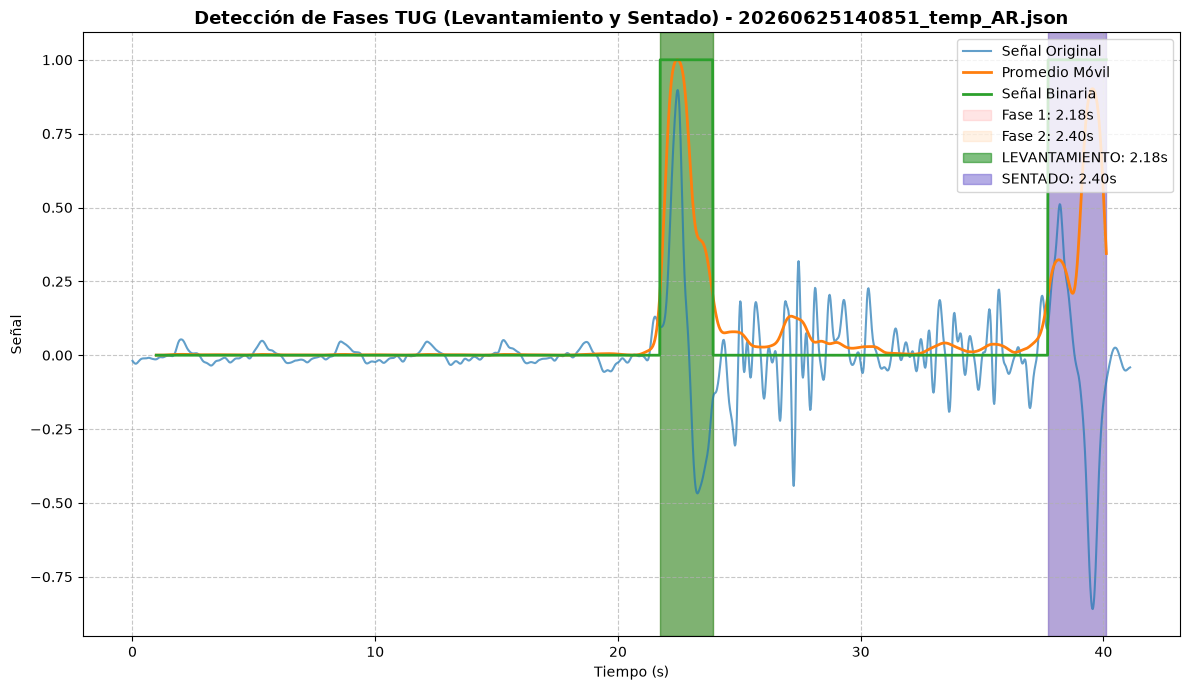

In [11]:
# ------------------------------------------------------------------------------
# Funciones de procesamiento y detección de fases
# ------------------------------------------------------------------------------
def filter_signal(signal, cutoff_hz=3, fs=50.0, order=4):
    """Filtro pasa-bajos Butterworth de fase cero (orden 4 numéricamente estable)."""
    nyquist = 0.5 * fs
    normal_cutoff = cutoff_hz / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

def energy_spectrum(signal, fs, window_size_samples, step_size_samples, apply_window=True):
    """Calcula el perfil temporal de energía con ventana deslizante."""
    energies = []
    times = []
    num_samples = len(signal)
    for start in range(0, num_samples - window_size_samples + 1, step_size_samples):
        end = start + window_size_samples
        window = signal[start:end]
        if apply_window:
            window = window * np.hanning(window_size_samples)
        energy = np.sum(window ** 2)
        energies.append(energy)
        t_center = (start + end) / 2 / fs
        times.append(t_center)
    energies = np.array(energies)
    times = np.array(times)
    if np.max(np.abs(energies)) > 0:
        energies = energies / np.max(np.abs(energies))
    return times, energies

def promediomovil(senal, ventana=50, fs=50.0):
    """Calcula el promedio móvil normalizado."""
    senal = np.array(senal, dtype=float)
    kernel = np.ones(ventana) / ventana
    prom = np.convolve(senal, kernel, mode='valid')
    if np.max(prom) != 0:
        prom = prom / np.max(prom)
    t = (np.arange(len(prom)) + ventana - 1) / fs
    return t, prom

def binary_threshold(signal: np.ndarray, threshold: float = 0.2) -> np.ndarray:
    """Binariza la señal con base en un umbral de activación."""
    return (signal >= threshold).astype(int)

def detectar_fases_tug(tiempo, senal_binaria, duracion_minima=0.35, umbral_adaptativo=True, pmovil=None):
    """
    Detecta las fases de Levantamiento y Sentado en la prueba TUG.
    Incorpora correspondencia garantizada de transiciones y detección adaptativa
    del sentado para evitar omisiones por picos de menor amplitud en pacientes.
    """
    tiempo = np.asarray(tiempo)
    binaria = np.asarray(senal_binaria).astype(int)

    def _extraer_tramos(sig_bin):
        pad = np.pad(sig_bin, (1, 1), 'constant', constant_values=0)
        inicios = np.where(np.diff(pad) == 1)[0]
        fines = np.where(np.diff(pad) == -1)[0]
        tramos = []
        for ini, fin in zip(inicios, fines):
            t_ini = tiempo[min(ini, len(tiempo)-1)]
            t_fin = tiempo[min(fin, len(tiempo)-1)]
            dur = t_fin - t_ini
            if dur >= duracion_minima:
                tramos.append({
                    'inicio_tiempo': float(t_ini),
                    'fin_tiempo': float(t_fin),
                    'duracion': float(dur),
                    'inicio_indice': int(ini),
                    'fin_indice': int(fin)
                })
        return tramos

    fases_movimiento = _extraer_tramos(binaria)

    # Búsqueda adaptativa del sentado en la segunda mitad de la grabación
    if len(fases_movimiento) < 2 and umbral_adaptativo and pmovil is not None:
        n_medio = len(pmovil) // 2
        segunda_mitad = pmovil[n_medio:]
        max_segunda = np.max(segunda_mitad) if len(segunda_mitad) > 0 else 0
        if max_segunda > 0.05:
            umbral_local = max(0.08, max_segunda * 0.5)
            binaria_local = (pmovil >= umbral_local).astype(int)
            tramos_locales = _extraer_tramos(binaria_local)
            if len(fases_movimiento) >= 1:
                t_fin_primera = fases_movimiento[0]['fin_tiempo']
                candidatos = [t for t in tramos_locales if t['inicio_tiempo'] > t_fin_primera + 1.0]
                if candidatos:
                    fases_movimiento.append(candidatos[-1])

    fases = {'levantamiento': None, 'sentado': None, 'todas_las_fases': fases_movimiento}
    if len(fases_movimiento) >= 1:
        fases['levantamiento'] = fases_movimiento[0]
    if len(fases_movimiento) >= 2:
        fases['sentado'] = fases_movimiento[-1]

    return fases

def graficar_fases_tug(tiempo, senal_original, senal_binaria, t_movil, pmovil, fases, titulo="Detección de Fases TUG"):
    """Genera el gráfico comparativo con sombreados para levantamiento y sentado."""
    plt.figure(figsize=(12, 7))
    plt.plot(tiempo, senal_original, label='Señal Original', alpha=0.7)
    plt.plot(t_movil, pmovil, label='Promedio Móvil', linewidth=2)
    plt.plot(t_movil, senal_binaria, label='Señal Binaria', linewidth=2)

    colores = ['#ff9999', '#ffcc99', '#df9fdf', '#d2b48c']
    for i, fase in enumerate(fases['todas_las_fases']):
        plt.axvspan(fase['inicio_tiempo'], fase['fin_tiempo'], alpha=0.25,
                    color=colores[i % len(colores)], label=f'Fase {i+1}: {fase["duracion"]:.2f}s')

    if fases['levantamiento']:
        lev = fases['levantamiento']
        plt.axvspan(lev['inicio_tiempo'], lev['fin_tiempo'], alpha=0.5, color='green',
                    label=f'LEVANTAMIENTO: {lev["duracion"]:.2f}s')
    if fases['sentado']:
        sent = fases['sentado']
        plt.axvspan(sent['inicio_tiempo'], sent['fin_tiempo'], alpha=0.5, color='slateblue',
                    label=f'SENTADO: {sent["duracion"]:.2f}s')

    plt.xlabel("Tiempo (s)")
    plt.ylabel("Señal")
    plt.title(titulo, fontsize=13, fontweight='bold')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

def imprimir_resumen_fases(fases):
    """Imprime las métricas temporales de las fases detectadas."""
    print("\n" + "=" * 60)
    print("RESUMEN DE FASES TUG DETECTADAS")
    print("=" * 60)
    print(f"Total de fases de movimiento detectadas: {len(fases['todas_las_fases'])}")

    if fases['levantamiento']:
        lev = fases['levantamiento']
        print(f"\n🚶 FASE DE LEVANTAMIENTO:")
        print(f"   Tiempo inicio: {lev['inicio_tiempo']:.2f} s")
        print(f"   Tiempo fin:    {lev['fin_tiempo']:.2f} s")
        print(f"   Duración:      {lev['duracion']:.2f} s")
    else:
        print("\n❌ No se detectó fase de levantamiento")

    if fases['sentado']:
        sent = fases['sentado']
        print(f"\n🪑 FASE DE SENTADO:")
        print(f"   Tiempo inicio: {sent['inicio_tiempo']:.2f} s")
        print(f"   Tiempo fin:    {sent['fin_tiempo']:.2f} s")
        print(f"   Duración:      {sent['duracion']:.2f} s")
    else:
        print("\n❌ No se detectó fase de sentado")

    print("\n📊 Detalle de todas las fases detectadas:")
    for i, f in enumerate(fases['todas_las_fases']):
        print(f"   Fase {i+1}: {f['inicio_tiempo']:.2f}s -> {f['fin_tiempo']:.2f}s (Duración: {f['duracion']:.2f}s)")
    print("=" * 60)

# ------------------------------------------------------------------------------
# Demostración interactiva de detección de fases (Levantamiento y Sentado)
# ------------------------------------------------------------------------------
# Ejemplo con un paciente aceptado de Santa Marta (AR)

lateral = "espina_base"
canal_senal = "b"   # Gyroscope Y (flexión/extensión del tronco)
indice_prueba = 0

try:
    pruebas_data = cargar_prueba_adaptada(muestra_archivo, carpeta_base=CARPETA_DATOS, fs_destino=50.0)
    clave_muestra, time, asignal = extraer_senal(pruebas_data, indice_prueba, lateral, canal_senal)

    asignalfiltered = filter_signal(asignal, cutoff_hz=3, fs=50.0, order=4)
    times, energies = energy_spectrum(asignalfiltered, fs=50.0, window_size_samples=50, step_size_samples=1, apply_window=True)

    t_movil, pmovil = promediomovil(energies, ventana=50, fs=50.0)
    binary = binary_threshold(pmovil, threshold=0.2)

    # Detección de fases robusta con lógica adaptativa para el sentado
    fases_det = detectar_fases_tug(t_movil, binary, duracion_minima=0.35, umbral_adaptativo=True, pmovil=pmovil)
    imprimir_resumen_fases(fases_det)
    graficar_fases_tug(time, asignalfiltered, binary, t_movil, pmovil, fases_det,
                       titulo=f"Detección de Fases TUG (Levantamiento y Sentado) - {muestra_archivo}")

except Exception as e:
    print(f"Error al graficar fases TUG: {e}")


## MÓDULO 6: Detección y Gráfica de Giros (Velocidad Angular)
Como se analizó en la literatura de referencia (*Molero Mateo et al.*) y en la **Reunión #6 con Domiciano Rincón**, la fase de **giro** (el giro de 180° en el cono y el giro previo al sentado) es el biomarcador cinemático más sensible para diferenciar pacientes con Enfermedad de Parkinson temprana de sujetos sanos.

En las brigadas (con sensor L5 orientado con gravedad en X), el *yaw* se registra en `gyroscope.x` (`signal='a'`) o `gyroscope.z` (`signal='g'` en pruebas antiguas).

Este módulo:
1. Procesa la velocidad angular de giro con filtro Butterworth pasa-bajos, espectro de energía y promedio móvil.
2. Binariza la señal para identificar los intervalos exactos de los giros de 180°.
3. Extrae métricas clave: tiempo de inicio, fin, duración y velocidad angular pico (°/s).
4. Genera la visualización comparativa con las cuatro curvas solicitadas (señal filtrada, energía, promedio móvil y señal binaria) y sombreado de los giros.

In [8]:
muestra_giro = "20260627150939_temp_R.json"


🌀 RESUMEN DE INTERVALOS DE GIRO DETECTADOS
Total de giros identificados: 4

🔄 GIRO #1:
   Tiempo inicio:       8.42 s
   Tiempo fin:          9.82 s
   Duración del giro:   1.40 s
   Velocidad pico:      0.60 (u. norm)

🔄 GIRO #2:
   Tiempo inicio:       12.86 s
   Tiempo fin:          14.44 s
   Duración del giro:   1.58 s
   Velocidad pico:      0.92 (u. norm)

🔄 GIRO #3:
   Tiempo inicio:       35.22 s
   Tiempo fin:          36.66 s
   Duración del giro:   1.44 s
   Velocidad pico:      0.48 (u. norm)

🔄 GIRO #4:
   Tiempo inicio:       39.60 s
   Tiempo fin:          41.20 s
   Duración del giro:   1.60 s
   Velocidad pico:      0.77 (u. norm)


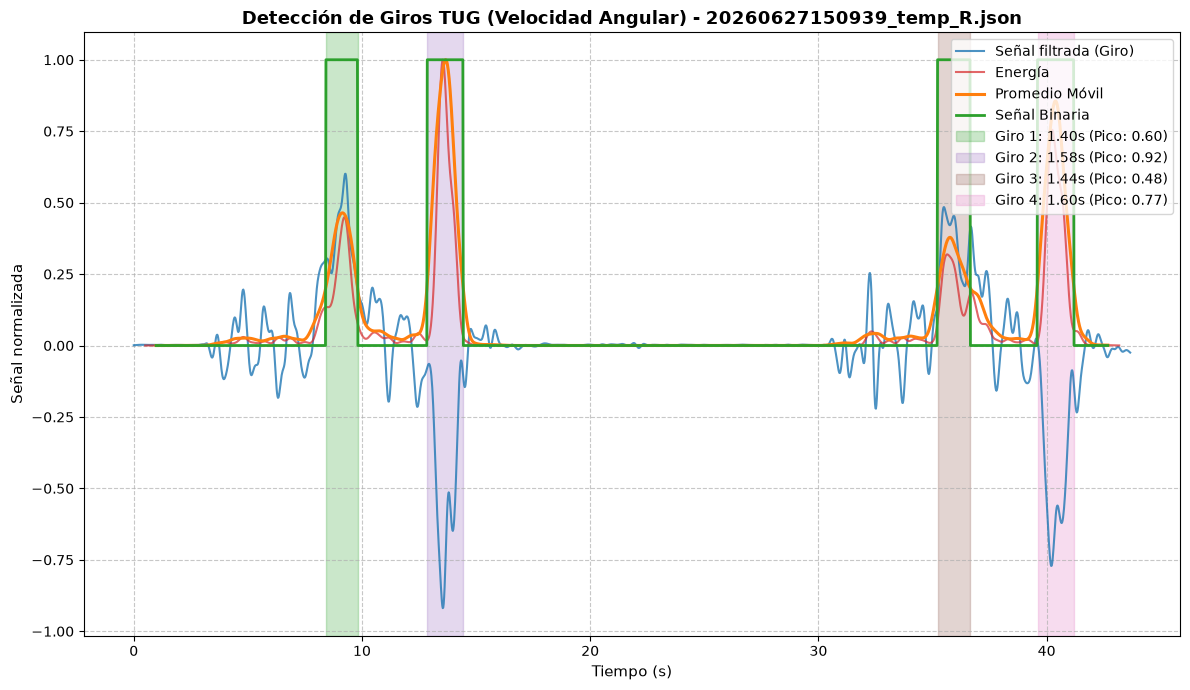

In [9]:
# ------------------------------------------------------------------------------
# Función: detectar_intervalos_giro
# ------------------------------------------------------------------------------
def detectar_intervalos_giro(tiempo, senal_gyro, fs=50.0, umbral=0.2, duracion_minima=0.5, ventana_energia=50):
    """
    Detecta los intervalos de giro TUG a partir de la velocidad angular de la espina baja.
    """
    tiempo = np.asarray(tiempo)
    sig = np.asarray(senal_gyro, dtype=float)

    # 1. Filtro pasa-bajos
    sig_filtered = filter_signal(sig, cutoff_hz=3, fs=fs, order=4)

    # 2. Espectro de energía
    t_e, energies = energy_spectrum(sig_filtered, fs=fs, window_size_samples=ventana_energia,
                                    step_size_samples=1, apply_window=True)

    # 3. Promedio móvil y binarización
    t_movil, pmovil = promediomovil(energies, ventana=ventana_energia, fs=fs)
    binary = binary_threshold(pmovil, threshold=umbral)

    # 4. Transiciones con padding para evitar cortes numéricos
    pad = np.pad(binary, (1, 1), 'constant', constant_values=0)
    inicios = np.where(np.diff(pad) == 1)[0]
    fines = np.where(np.diff(pad) == -1)[0]

    intervalos = []
    for ini, fin in zip(inicios, fines):
        t_ini = t_movil[min(ini, len(t_movil)-1)]
        t_fin = t_movil[min(fin, len(t_movil)-1)]
        dur = t_fin - t_ini
        if dur >= duracion_minima:
            mask = (tiempo >= t_ini) & (tiempo <= t_fin)
            pico_vel = np.max(np.abs(sig_filtered[mask])) if np.any(mask) else 0.0
            intervalos.append({
                'giro_num': len(intervalos) + 1,
                'inicio': float(t_ini),
                'fin': float(t_fin),
                'duracion': float(dur),
                'velocidad_pico': float(pico_vel)
            })

    return {
        'intervalos': intervalos,
        't_movil': t_movil,
        't_e': t_e,
        'energies': energies,
        'pmovil': pmovil,
        'binary': binary,
        'sig_filtered': sig_filtered
    }

# ------------------------------------------------------------------------------
# Función: graficar_giros_tug
# ------------------------------------------------------------------------------
def graficar_giros_tug(tiempo, sig_filtered, t_e, energies, t_movil, pmovil, binary, intervalos_giro, titulo="Detección de Giros TUG"):
    """
    Grafica las curvas de giro (Señal filtrada, Energía, Promedio Móvil y Señal Binaria)
    resaltando los giros de 180° detectados con sus duraciones y velocidades pico.
    """
    plt.figure(figsize=(12, 7))

    # Curvas comparativas de referencia
    plt.plot(tiempo, sig_filtered, label='Señal filtrada (Giro)', color='tab:blue', alpha=0.8)
    plt.plot(t_e, energies, label='Energía', color='tab:red', alpha=0.7)
    plt.plot(t_movil, pmovil, label='Promedio Móvil', color='tab:orange', linewidth=2.2)
    plt.plot(t_movil, binary, label='Señal Binaria', color='tab:green', linewidth=2.0)

    # Sombreado de cada giro detectado
    colores_giro = ['#2ca02c', '#9467bd', '#8c564b', '#e377c2']
    for i, g in enumerate(intervalos_giro):
        c = colores_giro[i % len(colores_giro)]
        plt.axvspan(g['inicio'], g['fin'], alpha=0.25, color=c,
                    label=f"Giro {g['giro_num']}: {g['duracion']:.2f}s (Pico: {g['velocidad_pico']:.2f})")

    plt.xlabel("Tiempo (s)", fontsize=11)
    plt.ylabel("Señal normalizada", fontsize=11)
    plt.title(titulo, fontsize=13, fontweight='bold')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

def imprimir_resumen_giros(intervalos_giro):
    """Imprime las métricas biomecánicas de los giros detectados."""
    print("\n" + "=" * 60)
    print("🌀 RESUMEN DE INTERVALOS DE GIRO DETECTADOS")
    print("=" * 60)
    print(f"Total de giros identificados: {len(intervalos_giro)}")
    for g in intervalos_giro:
        print(f"\n🔄 GIRO #{g['giro_num']}:")
        print(f"   Tiempo inicio:       {g['inicio']:.2f} s")
        print(f"   Tiempo fin:          {g['fin']:.2f} s")
        print(f"   Duración del giro:   {g['duracion']:.2f} s")
        print(f"   Velocidad pico:      {g['velocidad_pico']:.2f} (u. norm)")
    print("=" * 60)

# ------------------------------------------------------------------------------
# Demostración interactiva de detección de giros
# ------------------------------------------------------------------------------
# Archivo con repetición de prueba TUG (paciente R)

lateral_giro = "espina_base"
canal_giro = "a"  # En brigada, rotación horizontal en L5 corresponde a 'a' (gyro X)

try:
    pruebas_giro = cargar_prueba_adaptada(muestra_giro, carpeta_base=CARPETA_DATOS, fs_destino=50.0)
    clave_g, time_g, asignal_g = extraer_senal(pruebas_giro, 0, lateral_giro, canal_giro)

    res_giros = detectar_intervalos_giro(time_g, asignal_g, fs=50.0, umbral=0.2, duracion_minima=0.5)
    imprimir_resumen_giros(res_giros["intervalos"])
    graficar_giros_tug(time_g, res_giros["sig_filtered"], res_giros["t_e"], res_giros["energies"],
                       res_giros["t_movil"], res_giros["pmovil"], res_giros["binary"],
                       res_giros["intervalos"],
                       titulo=f"Detección de Giros TUG (Velocidad Angular) - {muestra_giro}")

except Exception as e:
    print(f"Error al graficar giros TUG: {e}")
